<!-- d2l:prose id=api-md-1 fw=all -->

# Models behind an API


Every model in this chapter so far ran on our own GPU. We read its files,
ran its tensors in the book's code, prompted it, scored it and opened it up.
None of these models had more than a few billion parameters.

The open models that people use most are far larger. DeepSeek-V4.1-Flash,
whose weights anyone may download, has about three quarters of a trillion
parameters, more than a server with eight 40 GB GPUs can hold even at four
bits per weight. Yet anyone with an account can send it a grade-school word
problem and read the answer a second or two later, for less than a hundredth
of a cent. The model is then somebody else's service, reached through an
*application programming interface* (API): we send a request over the
network and receive text. What can we still measure about a model that we
cannot hold, and how do we keep those measurements as trustworthy as the
earlier ones?

A hosted model shows its client three things: a protocol, a price and
limits. The protocol is the *chat-completions* request, which OpenAI
introduced with its chat models in 2023 and which nearly every company that
hosts models, and every local server, has since adopted. The price is
charged per token, for what we send and for what comes back. The limits are
of two kinds: a service refuses requests that arrive too fast, and it cannot
return most of what we read from our own models.

A service says little about itself, so whatever we learn about it we must
time and count from outside. The client becomes the measuring instrument.
Its first question, how many requests to send at once, is older than the
computer: telephone engineers developed queueing theory to decide how many
lines an exchange needs. And since a service changes without notice and
cannot be run again, each of its numbers needs a date, the name of the
company that served it, a cost, and a stored copy of the response.

We read the protocol, build the client, and run three numbered
experiments. Experiment 1 asks how many requests a server can usefully hold
at once, Experiment 2 which model to use and at what price, and Experiment 3
whether the same request returns the same reply. They reuse the prompt
builder of that section, the answer extractor and the GSM8K
problems of that section, and the paired comparison of
that section. At the end we ask which measurements of this
chapter can still be made through an API.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import asyncio
import collections
import contextlib
import datetime
import gc
import hashlib
import heapq
import json
import os
import pandas as pd
import random
import re
import sys
import time
from scipy import stats
from transformers.cli.serving.chat_completion import (
    UNUSED_CHAT_COMPLETION_FIELDS)

<!-- d2l:prose id=api-md-2 fw=all -->

## The Chat-Completions Protocol

### Hosted Models and Their Providers

Open weights are hosted by many companies at once, each of which sells
access by the token. We call such a company a *provider*. A *router* is a
service that puts one address and one account in front of many providers and
forwards each request to one of them. We use the router OpenRouter.
Providers differ in their prices and in the precision at which they serve
the same weights, so for each model we *pin* one provider: every request for
that model is served by the same company.

Calling a service costs money, and a service need not answer the same way
twice. The outputs on this page are therefore a recording. We sent every
request once, on 13 November 2026, and stored the responses, and the cells
below replay them without touching the network
(that section shows how). With a key of your own you can
make your own recording. Most of the next cell configures that machinery,
and only its four model names matter now. DeepSeek-V4.1-Flash is the model
that the code and the tables call the *flagship*. Qwen3.8-27B is a much
smaller open-weight model. The third, gpt-5-nano, is a *closed* model: its
weights are not published, and it appears in one test only. Qwen3-4B is the
model that will run behind a server on our own GPU.

In [3]:
API_MODE = os.environ.get('D2L_API_MODE', 'replay')  # or record, live
assert API_MODE in ('replay', 'record', 'live'), API_MODE
if API_MODE != 'replay' and not os.environ.get('OPENROUTER_API_KEY'):
    print(f'D2L_API_MODE={API_MODE} needs OPENROUTER_API_KEY: replaying')
    API_MODE = 'replay'
COST_CAP_USD = 5.0  # for all paid calls of one recording
RECORD_DIR = os.path.join('..', 'data', 'lm-api', 'record')
D2L_API_LOG_DIR = os.environ.get(  # logs outside the repository
    'D2L_API_LOG_DIR', os.path.expanduser('~/.local/share/d2l/lm-api'))
FLAGSHIP = 'deepseek/deepseek-v4.1-flash-1017'  # a dated snapshot id
SECOND = 'qwen/qwen3.8-27b'
CLOSED = 'openai/gpt-5-nano'  # probe only; its outputs are never committed
PROVIDERS = {FLAGSHIP: 'novita', SECOND: 'parasail', CLOSED: 'openai'}
LISTED = [FLAGSHIP, SECOND, CLOSED]  # the router models of the listing
LOCAL = 'Qwen/Qwen3-4B'  # behind transformers serve on our GPU
LOCAL_MODEL = f'{LOCAL}@{d2l.HF_REVISIONS[LOCAL]}'  # requests name id@rev
LOCAL_LIVE = API_MODE != 'replay' and torch.cuda.is_available()
LOCAL_MODE = API_MODE if LOCAL_LIVE else 'replay'
API_SHA1 = {  # the committed caches (zips), recorded 2026-11-13
    'lm-api-listing-v1': '4916ce668be31ed37947dac80bc094a70ee75efc',
    'lm-api-fields-v2': '9a12dce5a344f3e746de0c915fa3d2f505ee0f71',
    'lm-api-probe-v2': 'e9aea3523b8ced2383500d3772bfb82893733354',
    'lm-api-sweep-v1': '63250dccbf90eae6143b5affe74ae25972f514b1',
    'lm-api-gsm8k-v1': '1fbb38c4cf5f65fb69da5ba3719cd850ba768dc6',
    'lm-api-determinism-v1': '448e39446d960dac298a5db3a4e6c0b95051683b',
    'lm-api-effort-v1': '7480d44c1bc2b6f8d2ac90aadf9f50689b569b9b'}
for key, sha1 in API_SHA1.items():
    if sha1 is not None:
        d2l.DATA_HUB[key] = (d2l.LM_DATA_URL + key + '.zip', sha1)
rec = d2l.APIRecording(API_MODE, RECORD_DIR, COST_CAP_USD, PROVIDERS)

def usd(api, r):  # cost of one response: the provider's, else the listing's
    cost = r.usage.get('cost')
    return d2l.api_cost(r.usage, api.price) if cost is None else cost

print(f'mode {API_MODE}, cost cap {COST_CAP_USD} USD, local server '
      f'{"live" if LOCAL_LIVE else "replayed"}')

mode replay, cost cap 5.0 USD, local server replayed


<!-- d2l:prose id=api-md-3 fw=all -->

The cell reports that it replays. Two tables come before the first request,
and the first of them answers a question: what does a router know about its
providers? It publishes a *listing*, a table with one row for each provider
of a model. A row gives the context length, the prices and the request
fields that the provider says it supports, and most rows give the precision
of the served weights. The next cell prints the rows of our three pinned
providers from a snapshot that was taken during the recording.

In [4]:
WEIGHTS = {  # the open weights behind each model, at a pinned commit
    FLAGSHIP: ('deepseek-ai/DeepSeek-V4.1-Flash-1017',
               '1bae0e1088993b9b82de08f59de5be5a34e42170'),
    SECOND: ('Qwen/Qwen3.8-27B', '37561816e66b5b9153b1b64c10968c18c1e6f4a0'),
    LOCAL: (LOCAL, d2l.HF_REVISIONS[LOCAL])}
LISTING = rec.snapshot_listing(LISTED, WEIGHTS)  # taken when recording
rows = []
for m in LISTED:
    e = d2l.listing_endpoint(LISTING, m, PROVIDERS[m])
    price = d2l.price_from_listing(LISTING, m, PROVIDERS[m])
    rows.append({'model': m.split('/')[1], 'provider': e['tag'],
                 'context': e['context_length'], 'in': price.input,
                 'out': price.output, 'cached': price.cached_input,
                 **{f: f in e['supported_parameters'] for f in (
                     'seed', 'logprobs', 'reasoning')},
                 'json': 'structured_outputs' in e['supported_parameters']})
print(f'listing retrieved {LISTING["retrieved"]}; prices in USD per million '
      f'tokens')
print(pd.DataFrame(rows).to_string(index=False))

listing retrieved 2026-11-13T17:10:46Z; prices in USD per million tokens
                   model     provider  context    in  out  cached  seed  logprobs  reasoning  json
deepseek-v4.1-flash-1017   novita/fp8  1048576 0.165 0.66  0.0033  True      True       True  True
             qwen3.8-27b parasail/fp8   262144 0.240 2.20  0.0500  True      True       True  True
              gpt-5-nano       openai   400000 0.050 0.40  0.0050  True     False       True  True


<!-- d2l:prose id=api-md-4 fw=all -->

Prices are in dollars per million tokens, and a generated token costs four
to nine times as much as a prompt token. The ratio has a reason that we know
from decoding: the whole prompt passes through the model in one parallel
step, while every generated token needs a step of its own. The column
`cached` is a much lower price for prompt tokens at the start of a request
that repeat the start of an earlier one. The provider has kept the keys and
values of that prefix, the key-value cache again, and need not compute them
a second time. The last four columns are claims, which we shall test. All of
these numbers are dated, since a listing changes without notice.

The suffix `fp8` in the provider column says that both pinned providers
serve 8-bit weights. For Qwen3.8-27B that is half the precision of the
release, which is in bf16. The flagship was released at low precision in
the first place, one part of its weights in 8 bits and the larger part
in 4.

Why not download these models, as before? The next cell multiplies each
parameter count by 2 bytes (bf16), 1 byte (fp8) and half a byte (4 bits), as
if all weights of a model had one precision. It reports the highest of the
three that fits one 24 GB card and servers with eight GPUs of 40 GB or
80 GB.

In [5]:
PRECISIONS = (('bf16', 2), ('fp8', 1), ('4 bits', 0.5))  # bytes/weight

def best_fit(n, gb):  # the highest precision whose weights fit in gb
    return next((p for p, b in PRECISIONS if n * b <= gb * 1e9), 'none')

rows = []
for m in (FLAGSHIP, SECOND, LOCAL):
    n = LISTING['hf'][m]['params']
    rows.append({'weights': LISTING['hf'][m]['repo'].split('/')[1],
                 'params (B)': n / 1e9,
                 **{f'{p} (GB)': n * b / 1e9 for p, b in PRECISIONS},
                 '24GB card': best_fit(n, 24), '8x40GB': best_fit(n, 8 * 40),
                 '8x80GB': best_fit(n, 8 * 80)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

                 weights  params (B)  bf16 (GB)  fp8 (GB)  4 bits (GB) 24GB card 8x40GB 8x80GB
DeepSeek-V4.1-Flash-1017       763.2     1526.4     763.2        381.6      none   none 4 bits
             Qwen3.8-27B        27.8       55.6      27.8         13.9    4 bits   bf16   bf16
                Qwen3-4B         4.0        8.0       4.0          2.0      bf16   bf16   bf16


<!-- d2l:prose id=api-md-5 fw=all -->

At four bits per weight the flagship still needs 382 GB, and its release,
with part of the weights in eight bits, needs more. Only the server with
eight 80 GB cards can hold it, and that is before a byte is spent on the
key-value cache. Qwen3.8-27B is another matter. At four bits it would fit
our 24 GB card, and we could indeed have run it ourselves. We call it
through a provider all the same, because Experiment 2 needs a second hosted
model, at a second company, to compare prices. Qwen3-4B fits the card in
bf16, which makes it our local model.

### Requests and Responses

A chat-completions request is a JSON object sent by HTTP `POST`. The first
request of this section reads as follows, apart from two fields that only
the router understands and to which we shall come.

```json
{"model": "deepseek/deepseek-v4.1-flash-1017",
 "messages": [{"role": "user",
               "content": "Carmen has $100, Samantha has $25 more ..."}],
 "temperature": 0,
 "seed": 0,
 "max_tokens": 512}
```

<!-- d2l:prose id=api-md-6 fw=all -->

The field `messages` holds the conversation as a list of roles and contents,
the structure that we passed to a chat template in
that section. Here the server applies the template, so the
client never sees the tokens that the model reads. Most other fields set the
sampler of that section. The fields `temperature` and `top_p`
shape the distribution from which a token is drawn, `max_tokens` bounds the
length of the reply, `stop` lists strings at which the reply ends, and
`seed` asks for a draw that can be repeated. Newer servers also accept the
bound on the length under the name `max_completion_tokens`.

A few fields request extras. `logprobs` asks for the log-probabilities of
the generated tokens, `response_format` for output that follows a JSON
schema, `n` for several alternative replies to one request, and `stream` for
the reply in pieces, called chunks, as it is generated.

The question in this request is the first of our GSM8K test problems, the
grade-school word problems with a number as the answer that we scored in
that section. The client that the next cell creates may spend
the fraction `share` of the recording's cost cap, and it switches off a
feature called reasoning, to which we come in a moment.

In [6]:
gsm_train = pd.read_parquet(d2l.download_keyed('gsm8k-train'))
gsm_test = pd.read_parquet(d2l.download_keyed('gsm8k-test'))
samples = pd.read_json(d2l.download_keyed('lm-gsm8k-samples-v1'),
                       lines=True)
# the 100 test problems of the scoring section, by its seeded rule
GSM_IDS = [int(i) for i in dict.fromkeys(samples.problem_id)]
assert GSM_IDS == list(np.random.default_rng(0).permutation(
    len(gsm_test))[:100])
flagship = rec.hosted(FLAGSHIP, rec.cache('lm-api-probe-v2', 'flagship'),
                      share=0.05, reasoning={'enabled': False})
question = [{'role': 'user', 'content': gsm_test.question[GSM_IDS[0]]}]
r = flagship.chat(question, temperature=0, seed=0, max_tokens=512)
print(r.text)
u = r.usage
print(f'finish {r.finish_reason}; {u["prompt_tokens"]} prompt and '
      f'{u["completion_tokens"]} completion tokens ({u["reasoning_tokens"]} '
      f'reasoning, {u["cached_tokens"]} cached)')
print(f'{r.t_total:.2f} s; served {r.model} by {r.provider}; '
      f'system_fingerprint {r.system_fingerprint}')
print(f'{u["cost"]:.6f} USD billed, {d2l.api_cost(u, flagship.price):.6f} '
      f'USD from the listing')

Let's break it down step by step.

1. **Carmen's money**:  
Carmen has $100.

2. **Samantha's money**:  
Samantha has $25 more than Carmen.  
So, Samantha = $100 + $25 = $125.

3. **Daisy's money**:  
Daisy has $50 more than Samantha.  
So, Daisy = $125 + $50 = $175.

4. **Total combined**:  
$100 + $125 + $175 = $400.

\[
\boxed{400}
\]
finish stop; 36 prompt and 118 completion tokens (0 reasoning, 0 cached)
1.46 s; served deepseek/deepseek-v4.1-flash-1017 by Novita; system_fingerprint None
0.000084 USD billed, 0.000084 USD from the listing


<!-- d2l:prose id=api-md-7 fw=all -->

The cell prints the text of the reply and a few numbers from the response,
which is again a JSON object. Abridged to the fields that we use, it reads

```json
{"model": "deepseek/deepseek-v4.1-flash-1017",
 "provider": "Novita",
 "choices": [{"finish_reason": "stop",
              "message": {"role": "assistant",
                          "content": "Let's break it down ..."}}],
 "usage": {"prompt_tokens": 36, "completion_tokens": 118,
           "cost": 0.000084}}
```

<!-- d2l:prose id=api-md-8 fw=all -->

The reply sits in a list called `choices`, which has one entry unless the
request asked for more with `n`. The most important part is the `usage`
block: 36 prompt tokens, 118 completion tokens and, an addition of this
router, the cost in dollars. The client cannot check these counts itself. It
never sees the rendered prompt, and for a closed model it has no tokenizer
either. With the released tokenizer of an open model we could count our own
words, and we still would not know what the server wrote around them. The
`usage` block is therefore the only record of what was processed and the
basis of the bill, here less than a hundredth of a cent.

The other fields are quickly told. The field `finish_reason` says why
generation ended: `stop` at the end-of-sequence token, `length` at
`max_tokens`. The field `model` names the model that served the request, and
the router adds the provider. A field `system_fingerprint` is meant to
identify the serving configuration, and it came back empty in every response
of our recording. The answer, 400, is correct.

In that section we let Qwen3 think before it answered, inside a
think block that we could read and count. Many hosted models *reason* in the
same way, and a service treats that text as output: it bills it as
completion tokens and counts it against `max_tokens`. This sets a trap.
Qwen3.8-27B reasons unless it is told not to. Of our 100 test problems we
send it the one with the longest reference solution, with a budget of 64
tokens, and then again with reasoning switched off and a budget of 1,024.

In [7]:
second = rec.hosted(SECOND, rec.cache('lm-api-probe-v2', 'second'),
                    share=0.05)
LONGEST = sorted(GSM_IDS, key=lambda i: -len(gsm_test.answer[i]))
hard = [{'role': 'user', 'content': gsm_test.question[LONGEST[0]]}]
trap = second.chat(hard, temperature=0, seed=0, max_tokens=64)  # thinks
u = trap.usage
print(f'content {trap.text!r}, finish {trap.finish_reason}, '
      f'{len(trap.reasoning or "")} characters of reasoning')
print(f'usage: {u["prompt_tokens"]} prompt, {u["completion_tokens"]} '
      f'completion, {u["reasoning_tokens"]} reasoning tokens')
assert trap.text == '' and trap.finish_reason == 'length'
assert u['reasoning_tokens'] == u['completion_tokens'] == 64
answer = second.chat(hard, temperature=0, seed=0, max_tokens=1024,
                     extra_body={'reasoning': {'enabled': False}})
u, last = answer.usage, answer.text.strip().splitlines()[-1]
print(f'thinking off: last line {last!r} (reference '
      f'{d2l.extract_answer(gsm_test.answer[LONGEST[0]])}), '
      f'{u["completion_tokens"]} completion tokens, finish '
      f'{answer.finish_reason}')
assert not u['reasoning_tokens']
assert answer.finish_reason == 'stop', 'thinking off did not finish either'

content '', finish length, 258 characters of reasoning
usage: 125 prompt, 64 completion, 64 reasoning tokens
thinking off: last line '**$168,000**' (reference 168000), 871 completion tokens, finish stop


<!-- d2l:prose id=api-md-9 fw=all -->

The first reply is empty. All 64 completion tokens were reasoning tokens,
and the budget ran out before the answer began. The response does return the
reasoning, 258 characters of it in a field of its own, but no answer. An
empty reply that ends with `length` and has as many reasoning tokens as
completion tokens is the signature of this failure. With reasoning off the
model writes 871 tokens and ends on the correct answer.

The cell prints the last line of that reply and not an extracted answer, for
a reason that is worth knowing. The reply uses `####` for its Markdown
headings, and the extractor of that section, which takes the
first number after the last `####`, would have returned 96,000, a number
under the last such heading. The extractor expects a format, and this
request showed the model none.

The three numbered experiments of this section all run with reasoning off,
so that every arm answers in the same mode and every token that we pay for
is one that we can read. Each of them asserts that no response contains
reasoning.

Services that reason usually provide a dial as well, on OpenRouter the field
`reasoning` with an `effort` of `low`, `medium` or `high`. We try it on the
flagship, with the five of our 100 problems that have the longest reference
solutions. The fifteen requests go out together through `d2l.chat_batch`, a
helper that that section shows, and the word `await` in
front of it waits until all of them have returned.

In [8]:
effort_api = rec.hosted(FLAGSHIP, rec.cache('lm-api-effort-v1', 'flagship'),
                        share=0.2)
EFFORTS = ('low', 'medium', 'high')
batch = [{'messages': [{'role': 'user', 'content': gsm_test.question[i]}],
          'temperature': 0, 'seed': 0, 'max_tokens': 16384,
          'extra_body': {'reasoning': {'effort': e}}}
         for e in EFFORTS for i in LONGEST[:5]]
results = await d2l.chat_batch(effort_api, batch, concurrency=15)
assert not any(isinstance(r, Exception) for r in results), results
effort = pd.DataFrame({
    'effort': [e for e in EFFORTS for _ in range(5)],
    'reasoning tokens': [r.usage['reasoning_tokens'] for r in results],
    'completion tokens': [r.usage['completion_tokens'] for r in results],
    'seconds': [r.t_total for r in results],
    'USD': [usd(effort_api, r) for r in results]})
medians = effort.groupby('effort', sort=False).median()
print('an anecdote: n = 5 problems per effort; medians')
print(medians.round({'reasoning tokens': 0, 'completion tokens': 0,
                     'seconds': 2, 'USD': 6}))
paired = effort['reasoning tokens'].to_numpy().reshape(3, 5)  # by problem
for e, t in zip(EFFORTS, paired):
    print(f'{e:6s} reasoning tokens per problem: {t.tolist()}')
for i, j in ((0, 1), (1, 2), (0, 2)):  # paired, problem by problem
    print(f'{EFFORTS[j]} above {EFFORTS[i]} on '
          f'{(paired[j] > paired[i]).sum()} of 5 problems')

an anecdote: n = 5 problems per effort; medians
        reasoning tokens  completion tokens  seconds       USD
effort                                                        
low                215.0              313.0     3.03  0.000222
medium             218.0              357.0     3.26  0.000252
high               316.0              429.0     3.91  0.000305
low    reasoning tokens per problem: [446, 103, 199, 215, 346]
medium reasoning tokens per problem: [218, 84, 300, 182, 474]
high   reasoning tokens per problem: [545, 142, 316, 248, 554]
medium above low on 2 of 5 problems
high above medium on 5 of 5 problems
high above low on 5 of 5 problems


<!-- d2l:prose id=api-md-10 fw=all -->

The dial is a request, and the model decides what to make of it. At `high`
the flagship spent more reasoning tokens than at either other setting on
each of the five problems: in the median about one and a half times as many,
at nearly 40% more cost than `low`. The settings `low` and `medium` could
not be told apart. Their medians lie within a few tokens of each other, and
`low` spent more than `medium` on three of the five problems. The response
has the same fields at every setting, and only the token counts in `usage`
show what the dial did. Five problems make an anecdote, of course, and the
cell says nothing about accuracy.

### Endpoints and Their Fields

Providers, routers and local servers all accept the protocol. An address at
which a server accepts it is called an *endpoint*. The router's is
`https://openrouter.ai/api/v1`, its *base URL*, to which the client appends
a path: `/chat/completions` for a request, `/models` for the list of models
that the endpoint offers. One client class therefore reaches every model of
this section, and to move from one endpoint to another it changes two
strings, the base URL and the model name.

Our local endpoint is `transformers serve`, the server that comes with the
Transformers library. We start it with *continuous batching*: the server
does not wait for a batch to finish, and admits a new request into the
running batch between two decoding steps. It serves Qwen3-4B and not a model
of the newer Qwen3.5 family that earlier sections used. Transformers'
continuous batching has no cache for the recurrent layers that Qwen3.5
mixes with its attention layers (that section), and the
server would run such a model one request at a time. Programs that
serve models are called serving engines, and that section
treats them in their own right. Here the server is only an object to
measure.

One flag deserves attention now: `--cb-max-memory-percent 0.2` gives the
server's key-value cache at most a fifth of the card's free memory. Left to
itself the server would claim most of that memory. A fifth leaves the card
room to spare, and it has a consequence that we shall meet again. A server
can decode only as many sequences at once as its cache has room for, so this
budget bounds the capacity that Experiment 1 will measure.

In [9]:
NO_THINK_LOCAL = {'extra_body': {'chat_template_kwargs': {
    'enable_thinking': False}}}
STORY_LOCAL = [{'role': 'user', 'content': 'Write a long story.'}]
LOCAL_HTTP = None  # the local endpoint's HTTP client (None: real HTTP)
if LOCAL_LIVE:
    server = d2l.LocalChatServer([
        os.path.join(os.path.dirname(sys.executable), 'transformers'),
        'serve', LOCAL_MODEL, '--continuous-batching', '--dtype', 'bfloat16',
        '--model-timeout', '-1', '--cb-max-memory-percent', '0.2',
        '--host', '127.0.0.1', '--port', '{port}'])
    LOCAL_URL = server.start()
    warm = d2l.ChatAPI(LOCAL_URL, LOCAL_MODEL, mode='live',
                       default_params=NO_THINK_LOCAL)
    tic = time.monotonic()
    warm.chat([{'role': 'user', 'content': 'Hello'}], max_tokens=8)
    print(f'{LOCAL_URL}: ready after {server.load_time:.0f} s, warm-up '
          f'request {time.monotonic() - tic:.1f} s')
    r = warm.chat(STORY_LOCAL, max_tokens=256)  # one request alone
    print(f'{r.usage["completion_tokens"]} tokens in {r.t_total:.1f} s: '
          f'{r.usage["completion_tokens"] / r.t_total:.1f} tokens/s')
else:  # the request hash keeps the host only, so any port replays
    server, LOCAL_URL = None, 'http://127.0.0.1/v1'
    print(f'{LOCAL_URL}: replayed from the committed caches')

def local(cache, mode=LOCAL_MODE):
    """A client of the local server, thinking switched off."""
    return rec.add(d2l.ChatAPI(LOCAL_URL, LOCAL_MODEL, cache=cache, mode=mode,
                               http_client=LOCAL_HTTP,
                               default_params=NO_THINK_LOCAL))

http://127.0.0.1/v1: replayed from the committed caches


<!-- d2l:prose id=api-md-11 fw=all -->

On this page the server does not start: its responses were recorded like
all the others.

That every endpoint accepts a request does not mean that every endpoint does
the same thing with it. We make the router refuse what it can: we forbid
fallbacks to other providers and set `require_parameters`, so that a request
fails unless the pinned provider lists every field in it. That still leaves
the provider that lists a field and ignores it. The only defense is to test
each field by its effect.

The next cell writes out two such *detection rules*. The field `seed` is
honoured if two requests with seed 7 return the same text and a third with
seed 8 returns a different one. The three requests sample at temperature 1
wherever the endpoint accepts a temperature, because at temperature 0
nothing is drawn and a seed has nothing to fix. The field `stop=['5']` is
honoured if a request to count from 1 to 10 returns a 4 and no 5. The rules
in the library follow the same pattern.

In [10]:
STORY = [{'role': 'user', 'content':
          'Write a short paragraph about a lighthouse keeper.'}]
COUNT = [{'role': 'user', 'content':
          'Count from 1 to 10, separated by commas.'}]

def seed_honoured(a, b, c):  # STORY with seed 7 twice (replicas), then 8
    return a.text == b.text != c.text

def stop_honoured(a):  # COUNT with stop=['5']
    return '4' in a.text and '5' not in a.text

FIELDS_FILE = os.path.join(rec.folder('lm-api-fields-v2'),
                           'lm-api-fields.csv')
LOCAL_NAME = 'Qwen3-4B (local server)'
if API_MODE != 'replay':  # replay reads the committed table
    off, on = ({'reasoning': {'enabled': s}} for s in (False, True))
    local_off, local_on = ({'chat_template_kwargs': {'enable_thinking': s}}
                           for s in (False, True))
    closed = rec.hosted(CLOSED, os.path.join(D2L_API_LOG_DIR, 'scratch',
                                             'closed-probe.jsonl'),
                        share=0.05)
    endpoints = {  # client, body of every test, thinking on and off,
        # output budget, the id /v1/models should list
        'DeepSeek-V4.1-Flash (Novita)': (flagship, off, on, off, 64,
                                         FLAGSHIP),
        'Qwen3.8-27B (Parasail)': (second, off, on, off, 64, SECOND),
        'gpt-5-nano (OpenAI)': (closed, None, on, off, 2048,
                                CLOSED)}  # a closed model thinks by default
    if LOCAL_LIVE:
        endpoints[LOCAL_NAME] = (local(rec.cache('lm-api-probe-v2', 'local')),
                                 local_off, local_on, local_off, 64, LOCAL)
    await d2l.record_field_probe(
        FIELDS_FILE, endpoints, local_name=LOCAL_NAME, listing=LISTING,
        providers=PROVIDERS, story=STORY, count=COUNT,
        rules={'seed': seed_honoured, 'stop': stop_honoured})

<!-- d2l:prose id=api-md-12 fw=all -->

The table of verdicts has one column per endpoint, named by its model:
`flagship` is DeepSeek-V4.1-Flash at Novita, `Qwen3.8-27B` is served by
Parasail, `gpt-5-nano` by OpenAI, and `local` is our own server. Three
verdicts fill most cells. *Rejected* means an error status, *ignored* that
the request succeeded and the rule failed, and *honoured* that the rule
held. Two more mark half-answers: *partial*, where the endpoint did part of
what the field asked, and *inconsistent*, where the response contradicts
itself. Most rows are named by the field that they send, and we explain the
others as we come to them.

In [11]:
SHORT = {'DeepSeek-V4.1-Flash (Novita)': 'flagship',
         'Qwen3.8-27B (Parasail)': 'Qwen3.8-27B',
         'gpt-5-nano (OpenAI)': 'gpt-5-nano', LOCAL_NAME: 'local'}
SENT = {'seed': ['seed'], 'n=2': ['n'],  # the OpenAI fields each test sends
        'logprobs, top 5': ['logprobs', 'top_logprobs'], "stop=['5']":
        ['stop'], 'response_format': ['response_format'],
        'max_completion_tokens=16': ['max_completion_tokens'],
        'stream usage': ['stream_options']}
fields = pd.read_csv(FIELDS_FILE).replace({'endpoint': SHORT})
table = fields.pivot(index='field', columns='endpoint', values='status')
table = table.loc[fields.field.unique(), fields.endpoint.unique()]
table['serve declares unused'] = [
    ('yes' if set(SENT[f]) <= UNUSED_CHAT_COMPLETION_FIELDS else 'no')
    if f in SENT else '' for f in table.index]
print(table.to_string())
batching = fields[(fields.endpoint == 'local') &
                  (fields.field == '4 concurrent requests')].iloc[0]
LOCAL_BATCHES = batching.status != 'serialized'
print(f'local server: {batching.status} ({batching.evidence})')

endpoint                  flagship   Qwen3.8-27B    gpt-5-nano     local serve declares unused
field                                                                                         
seed                       ignored       ignored       ignored  honoured                    no
n=2                        ignored       ignored       ignored   ignored                   yes
logprobs, top 5            partial      honoured      rejected   ignored                   yes
stop=['5']                honoured      honoured      rejected   ignored                    no
response_format           honoured      honoured      honoured   ignored                   yes
thinking switch           honoured      honoured      rejected  honoured                      
max_completion_tokens=16  honoured      honoured  inconsistent   ignored                   yes
prompt log-probabilities   ignored       ignored       ignored  rejected                      
stream usage              honoured      honoured  

<!-- d2l:prose id=api-md-13 fw=all -->

Read the `seed` row first. All three hosted endpoints list `seed`, and none
of the three returned the same text for the same seed. The rule cannot tell
whether a provider dropped the seed or applied it to logits that differ from
one request to the next, which Experiment 3 will show they do. For a client
the two come to the same thing.

The flagship's provider lists log-probabilities and returned them for only
part of the reply. No endpoint returned two choices for `n=2`. The row
`prompt log-probabilities` sends two fields that are not in the protocol and
that some servers add, and no endpoint answered them with the
log-probabilities of a prompt.

Now read down the column `local`. Our own server is the least obliging of
the four: it honours the seed and the thinking switch, and it ignores
`stop`, `logprobs`, `response_format`, `n=2` and the token cap. Having the
weights on our own card is no help as long as we speak to them through a
server that somebody else wrote. What a field does is decided by the program
that answers.

The remaining rows need less attention. The row `thinking switch` turns
reasoning on and off, and `stream usage` asks a streamed reply to end with
its `usage` block. The row `/v1/models` asks the endpoint to list its
models. It reads *ignored* for the local server, which builds its list from
the branches in the Hugging Face cache, where a model that was downloaded at
a pinned commit, like ours, has none. The server serves a model that it does
not list. The last row sends four requests at once. It reads *batched* if
the slowest of them took less than twice as long as a single request, and
*rate-limited* if the endpoint answered with the status 429, "too many
requests". Three endpoints batched the four requests. The provider of
Qwen3.8-27B answered with 429s, and the client retried until every request
had succeeded.

Two columns hold details that a first reading can skip. All three rejections
in the column of the closed model came from the router. It refused
`logprobs` and `stop` because the listing of this model lacks both fields
and we had set `require_parameters`, and it refused the switch that turns
reasoning off because it marks reasoning as mandatory for this model. The
*inconsistent* in the same column is stranger. Under a cap of 16 completion
tokens the `usage` block reported more reasoning tokens than completion
tokens. Our statement that reasoning tokens are counted inside completion
tokens is therefore limited to the endpoints of our experiments.

The last column compares the local server with its own source code, which
keeps a list of request fields that the server accepts and does not act on.
The server agrees with that list in all rows but two. It ignores `stop`,
which is not on the list, and it honours `stream usage` although
`stream_options` is on it, because it sends `usage` with the last chunk of
every stream, asked or not. A declaration in the source is a claim, like a
row in a listing.

A table like this one is a snapshot of a single day, and it is cheap. The
two open-weight columns cost less than a cent together. Make one before any
experiment that relies on a field.

## A Measuring Client

### Records, Replays and Cost

Every call so far went through one class, `d2l.ChatAPI`. Its plumbing is in
the library, and the methods that carry ideas are shown here. The first idea
is the record. A response from a service cannot be recomputed, so the client
appends each one to a file and looks there before it sends anything. The
lookup key is a hash of the request, and the design lies in what enters it.

Every field that can change the response must be in the hash: the host, the
model, the messages, the sampling and format fields, and the routing fields,
since a different provider is a different service. If one is missing, the
cache silently returns a stale answer to a changed question. Nothing secret
may be in the hash, which excludes the headers with the API key. The key has
a second reason to stay out: with it, a reader who has another key, or none
at all, would miss every entry. Nor does the hash hold anything that leaves
the response unchanged, such as the choice of streaming.

In [12]:

def request_hash(base_url, model, messages, params, replica=0):
    """sha256 of the canonical JSON (sorted keys, no whitespace, UTF-8) of
    what can change a response: the endpoint's hostname, the model, the
    messages, the merged parameters (None values dropped) without the
    transport fields stream, stream_options, timeout and extra_headers, and
    the client-side replica number."""
    from urllib.parse import urlsplit  # not in the d2l library preamble
    transport = ('stream', 'stream_options', 'timeout', 'extra_headers')
    params = d2l._chat_merge(params, {})  # drops None values at every level
    params = {k: v for k, v in params.items() if k not in transport}
    key = {'host': urlsplit(base_url).hostname, 'model': model,
           'messages': messages, 'params': params, 'replica': replica}
    blob = json.dumps(key, sort_keys=True, separators=(',', ':'),
                      ensure_ascii=False)
    return hashlib.sha256(blob.encode('utf-8')).hexdigest()

<!-- d2l:prose id=api-md-14 fw=all -->

One part of the key exists only on the client, the number `replica`. Without
it two identical requests would share one cache entry, and we shall soon
want twenty answers to one question. Which of the five variations in the
next cell should change the hash?

In [13]:
url = 'https://openrouter.ai/api/v1'
model = 'deepseek/deepseek-v4.1-flash-1017'
messages = [{'role': 'user', 'content': 'What is 17 * 23?'}]
pin = {'only': ['novita'], 'allow_fallbacks': False,
       'require_parameters': True}
params = {'temperature': 0, 'seed': 0, 'max_tokens': 64,
          'extra_body': {'provider': pin}}
variants = {
    'request': (url, params, 0),
    'stream=True': (url, {**params, 'stream': True}, 0),
    'another API key': (url, {**params, 'extra_headers': {
        'Authorization': 'Bearer another-key'}}, 0),
    'replica=1': (url, params, 1),
    'seed=1': (url, {**params, 'seed': 1}, 0),
    'provider parasail': (url, {**params, 'extra_body': {
        'provider': {**pin, 'only': ['parasail']}}}, 0)}
for name, (u, p, replica) in variants.items():
    print(f'{name:18s}', request_hash(u, model, messages, p, replica)[:12])

request            7cc7806f70bb
stream=True        7cc7806f70bb
another API key    7cc7806f70bb
replica=1          d894f66c39ee
seed=1             55eaa444de1b
provider parasail  cda240a315d9


<!-- d2l:prose id=api-md-15 fw=all -->

Streaming and a different API key leave the hash unchanged. A replica
number, a seed and a provider each change it.

The client uses the cache in one of three modes. In mode `replay` a miss
raises an error, so a page that replays can never reach the network. Mode
`record` sends only what is missing, and mode `live` always sends. A replay
returns one recorded draw from the service. It makes this page reproducible,
and it does not make the service deterministic, as we shall see.

The second idea is that cost is arithmetic on `usage`. A provider charges
per token at up to three rates, in dollars per million tokens:
$r_\textrm{in}$ for prompt tokens, $r_\textrm{out}$ for completion tokens,
and the lower rate $r_\textrm{cache}$ for the prompt tokens of a prefix that
is still in its *prompt cache* from an earlier request. A response with
$n_\textrm{in}$ prompt tokens, of which $n_\textrm{cache}$ were cached, and
$n_\textrm{out}$ completion tokens costs

$$
\frac{(n_\textrm{in} - n_\textrm{cache})\, r_\textrm{in}
+ n_\textrm{cache}\, r_\textrm{cache}
+ n_\textrm{out}\, r_\textrm{out}}{10^6}
$$

dollars. Reasoning tokens need no term of their own, because they are part
of $n_\textrm{out}$. For the first response of this section, with 36 prompt
tokens, none of them cached, and 118 completion tokens, Novita's rates of
0.165 and 0.66 dollars per million tokens give 0.000084 dollars, the amount
that the router billed.

In [14]:

PricePoint = collections.namedtuple(  # USD per `per` tokens
    'PricePoint', ['input', 'output', 'cached_input', 'per'],
    defaults=(None, 1_000_000))


def api_cost(usage, price):
    """Cost in USD of one response, ((p - c) input + c cached_input +
    o output) / per, with p prompt, c cached and o completion tokens from
    usage (reasoning tokens are inside o). cached_input None means no
    discount; missing cached tokens count as 0; missing prompt or
    completion tokens raise ValueError."""
    p, o = usage.get('prompt_tokens'), usage.get('completion_tokens')
    if p is None or o is None:
        raise ValueError(f'usage lacks prompt or completion tokens: {usage}')
    c = usage.get('cached_tokens') or 0
    cached = price.input if price.cached_input is None else price.cached_input
    return ((p - c) * price.input + c * cached + o * price.output) / price.per

<!-- d2l:prose id=api-md-16 fw=all -->

Round numbers are easier to check by hand. At the same rates, a response
with 1,000 prompt tokens and 300 completion tokens should cost
$0.000165 + 0.000198 = 0.000363$ dollars. The next cell checks this. It then
asks the listing what a second provider, DeepSeek itself, charges for the
same model at 02:00 and at 12:00 UTC of one Thursday.

In [15]:
novita = d2l.price_from_listing(LISTING, FLAGSHIP, 'novita')
print(f'Novita, USD per million tokens: {novita.input} in, {novita.output} '
      f'out, {novita.cached_input} cached in')
usage = {'prompt_tokens': 1000, 'completion_tokens': 300}
cost = d2l.api_cost(usage, novita)
assert abs(cost - (1000 * novita.input + 300 * novita.output) / 1e6) < 1e-15
print(f'1,000 prompt and 300 completion tokens: {cost:.6f} USD')
assert f'{cost:.6f}' == '0.000363', 'the text quotes 0.000363 USD: update it'
for hour in (2, 12):  # a Thursday, inside and outside a peak window
    when = datetime.datetime(2026, 11, 12, hour, tzinfo=datetime.timezone.utc)
    price = d2l.price_from_listing(LISTING, FLAGSHIP, 'deepseek', when=when)
    print(f'DeepSeek at {when:%a %H:%M} UTC: {price.input:.3f} in, '
          f'{price.output:.3f} out')

Novita, USD per million tokens: 0.165 in, 0.66 out, 0.0033 cached in
1,000 prompt and 300 completion tokens: 0.000363 USD
DeepSeek at Thu 02:00 UTC: 0.300 in, 1.200 out
DeepSeek at Thu 12:00 UTC: 0.150 in, 0.600 out


<!-- d2l:prose id=api-md-17 fw=all -->

At two in the morning, UTC, DeepSeek's own endpoint lists twice its noon
price. That hour is ten in the morning in Beijing, and the listing doubles
the price for the working hours of a Chinese weekday. A cost therefore needs
the hour of the request as well as the day.

Since the cost of a request can be bounded before it is sent, the client
also enforces a budget. Before each live call it reserves the worst case,
one prompt token per byte of the request plus `max_tokens` completion
tokens, and it refuses to send when the reservation would cross the cap.

### Retries and Full-Jitter Backoff

A service fails in ways that a local model does not. Connections drop,
requests time out, and a busy provider answers with the status 429,
sometimes with a header `Retry-After` that says how long to wait. The client
should retry these failures, but not a malformed request or a bad key (the
statuses 400 and 401), which would fail forever. How long should it wait?

The standard answer is *exponential backoff*: after the failed attempt $a$,
counted from 0, wait for the time $d_a = \min(d_{\max}, b\,2^a)$, with a
base $b$ and a cap $d_{\max}$. Every failure doubles the wait. But consider
many clients that fail at the same moment. If each of them waits $d_a$,
they all return together and fail together again. *Full jitter*
[@Brooker.2015] breaks the tie: each client sleeps for a time drawn
uniformly from $[0, d_a]$.

In [16]:

def backoff_delay(attempt, base=1.0, cap=60.0, rng=None, retry_after=None):
    """Full-jitter sleep after failed attempt `attempt` (0, 1, ...): uniform
    on [0, min(cap, base 2^attempt)], and at least the server's
    Retry-After."""
    rng = rng or random
    return max(retry_after or 0, rng.uniform(0, min(cap, base * 2**attempt)))

<!-- d2l:prose id=api-md-18 fw=all -->

A uniform draw from $[0, d_a]$ has mean $d_a/2$. Suppose that each attempt
fails independently with probability $p$. This is the bold assumption of the
calculation, since a provider that has just rejected a request will probably
reject the next one as well, and we shall drop it shortly. The client sleeps
after attempt $a$ only if the attempts $0, \ldots, a$ all failed, which has
probability $p^{a+1}$. With at most $K$ retries the expected total sleep is
therefore

$$
\mathbb{E}[S] = \sum_{a=0}^{K-1} p^{a+1}\, \frac{d_a}{2}.
$$

Take $b = 1$ s and $d_{\max} = 60$ s. A client that fails six times in a row
sleeps $(1 + 2 + 4 + 8 + 16 + 32)/2 = 31.5$ s on average, against 63 s
without jitter. With $p = 0.3$ and $K = 6$ the terms are
$0.15, 0.09, 0.054, \ldots$, each 0.6 times the one before, and they sum to
0.3575 s. In words: even when three attempts in ten fail, retrying costs a
request about a third of a second on average. Backoff is cheap as long as
failure is the exception.

The method `achat` puts the parts in order: the cache lookup, the cost
reservation, then the retry loop. It is an `async` function, the first in
this book. Python suspends such a function at every `await`, here while it
sleeps or waits for the network, and runs other pending calls in the
meantime, all in one thread. This is how a single notebook cell keeps
dozens of requests in flight. A caller writes `await` in front of the call
to wait for its result, and a notebook cell may do so directly.

In [17]:
@d2l.add_to_class(d2l.ChatAPI)
async def achat(self, messages, *, replica=0, stream=False, **params):
    """One chat completion as a d2l.ChatResult. The cache answers first when
    the mode allows; a live call reserves its worst-case cost, retries
    connection errors, timeouts, 408, 429 and 5xx responses and error
    events inside a stream with full-jitter backoff (Retry-After as a
    floor), and raises at once on any other status."""
    import asyncio  # not in the d2l library preamble
    params = d2l._chat_merge(self.default_params, params)
    h = d2l.request_hash(self.base_url, self.model, messages, params, replica)
    self._stats['calls'] += 1
    hit = self._lookup(h, messages)  # raises ReplayMiss in replay mode
    if hit is not None:
        return hit
    reserved = self._reserve(messages, params)  # raises CostCapExceeded
    t_send, n_retries, n_429 = time.monotonic(), 0, 0
    created = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
    try:
        for attempt in range(self.max_retries + 1):
            try:
                out = await self._send(messages, params, stream, h, replica,
                                       attempt)
                break
            except Exception as e:
                retry, status, retry_after = self._retry_info(e)
                n_429 += status == 429
                if not retry or attempt == self.max_retries:
                    e.n_retries, e.n_429 = n_retries, n_429
                    raise
                n_retries += 1
                await asyncio.sleep(d2l.backoff_delay(
                    attempt, self.backoff_base, self.backoff_cap, self.rng,
                    retry_after))
    except BaseException:
        self._settle(reserved, 0.0)
        raise
    return self._record(h, messages, params, replica, out, t_send, created,
                        n_retries, n_429, reserved)

<!-- d2l:prose id=api-md-19 fw=all -->

The loop treats a `Retry-After` header as a floor under the jittered sleep,
and it counts every 429 itself. That takes a precaution. The client sends
its requests through the OpenAI Python package, which by default retries
twice on its own and would hide those failures from us, so its retries are
switched off.

The function `chat_batch` sends a list of requests with a bound on how many
are in flight, and it returns the results in the order of the requests. Its
few lines are the mechanism of all three experiments. The semaphore holds
`concurrency` permits. A request takes one before it is sent and gives it
back when its response has arrived, and at that moment the next request
starts. The call to `asyncio.gather` starts all requests and waits until the
last of them has returned.

In [18]:

async def chat_batch(api, requests, *, concurrency=8):
    """Send requests (dicts with 'messages', optionally 'replica' and request
    parameters) through api with at most `concurrency` in flight; results
    come in input order, a failed request as its exception. A replay miss
    or a capped call is not a result: once every request has finished (the
    paid ones are cached), the first d2l.ReplayMiss or d2l.CostCapExceeded
    is raised, with the whole list as its `results` attribute."""
    import asyncio  # not in the d2l library preamble
    semaphore = asyncio.Semaphore(concurrency)
    async def one(request):
        async with semaphore:
            try:
                request = dict(request)
                return await api.achat(request.pop('messages'), **request)
            except Exception as e:
                return e
    results = await asyncio.gather(*(one(r) for r in requests))
    for r in results:
        if isinstance(r, (d2l.ReplayMiss, d2l.CostCapExceeded)):
            r.results = results
            raise r
    return results

<!-- d2l:prose id=api-md-20 fw=all -->

We test the retry loop on `d2l.FakeChatServer`, a stand-in inside the
notebook's process that answers after a fixed service time, a given number
of requests at a time. Here it is scripted to answer 429 twice before it
succeeds, and then to answer 401.

In [19]:
hello = [{'role': 'user', 'content': 'Hello'}]
fake = d2l.FakeChatServer(0.01, 1, script=[429, 429, 200])
api = d2l.ChatAPI('http://fake.local/v1', 'fake-model', mode='live',
                  http_client=fake.transport())
r = api.chat(hello, max_tokens=8)
print(f'attempts {fake.n_requests}, 429s {r.n_429}, retries {r.n_retries}')
assert (fake.n_requests, r.n_429, r.n_retries) == (3, 2, 2)
fake = d2l.FakeChatServer(0.01, 1, script=[401])
api = d2l.ChatAPI('http://fake.local/v1', 'fake-model', mode='live',
                  http_client=fake.transport())
try:
    api.chat(hello, max_tokens=8)
except Exception as e:
    error = e
else:
    raise AssertionError('the 401 was not raised')
print(f'{type(error).__name__} after {fake.n_requests} attempt')
assert getattr(error, 'status_code', None) == 401 and fake.n_requests == 1

attempts 3, 429s 2, retries 2
AuthenticationError after 1 attempt


<!-- d2l:prose id=api-md-21 fw=all -->

The first request needed three attempts, and the client counted two 429s.
The second raised its error after one attempt. Next we check
the equation with 200,000 simulated clients.

In [20]:
p, K, rng = 0.3, 6, random.Random(0)
def total_sleep():
    sleep = 0.0
    for a in range(K):
        if rng.random() >= p:
            break
        sleep += d2l.backoff_delay(a, 1.0, 60.0, rng)
    return sleep
draws = np.array([total_sleep() for _ in range(200_000)])
formula = sum(p**(a + 1) * min(60, 2**a) / 2 for a in range(K))
print(f'E[S] = {formula:.4f} s; simulated {draws.mean():.4f} '
      f'+- {3 * draws.std() / np.sqrt(len(draws)):.4f} s (3 sigma)')

E[S] = 0.3575 s; simulated 0.3573 +- 0.0093 s (3 sigma)


<!-- d2l:prose id=api-md-22 fw=all -->

The simulation agrees with the formula. Jitter halves the mean sleep, which
is welcome, but that is not why it exists. The reason shows only when many
clients fail together. Their failures are then anything but independent, so
we leave the formula and simulate. In the last simulation 64 clients send at
the same instant to a server that admits ten requests in any window of one
second and rejects the rest, once with the fixed waits $d_a$ and once with
full jitter.

In [21]:
def retry_storm(n=64, rate=10, jitter=True, seed=0):
    """Simulated time: n clients send at t = 0 to a server that admits at
    most `rate` requests in any one-second window and rejects the rest; a
    rejected client sleeps and retries. Returns attempts and finish time."""
    rng, admitted = random.Random(seed), collections.deque()
    events, attempts, t_done = [(0.0, i, 0) for i in range(n)], 0, 0.0
    while events:
        t, i, a = heapq.heappop(events)
        attempts += 1
        while admitted and admitted[0] <= t - 1:
            admitted.popleft()
        if len(admitted) < rate:
            admitted.append(t)
            t_done = max(t_done, t)
        else:
            d = d2l.backoff_delay(a, rng=rng) if jitter else min(60, 2**a)
            heapq.heappush(events, (t + d, i, a + 1))
    return attempts, t_done

storms = {jitter: np.array([retry_storm(jitter=jitter, seed=k)
                            for k in range(200)]) for jitter in (False, True)}
print('over 200 seeds: median (min to max)')
for jitter, name in ((False, 'no jitter:  '), (True, 'full jitter:')):
    (a_lo, t_lo), (a_mid, t_mid), (a_hi, t_hi) = np.percentile(
        storms[jitter], [0, 50, 100], axis=0)
    print(f'{name} all done at {t_mid:.1f} s ({t_lo:.1f} to {t_hi:.1f}), '
          f'{a_mid:.0f} attempts ({a_lo:.0f} to {a_hi:.0f})')
fewer = (storms[True][:, 0] < storms[False][:, 0]).sum()
print(f'full jitter makes fewer attempts on {fewer} of 200 seeds')

over 200 seeds: median (min to max)
no jitter:   all done at 63.0 s (63.0 to 63.0), 238 attempts (238 to 238)
full jitter: all done at 14.5 s (8.3 to 31.4), 228 attempts (221 to 239)
full jitter makes fewer attempts on 197 of 200 seeds


<!-- d2l:prose id=api-md-23 fw=all -->

Without jitter the clients return in lockstep. Each wave gets ten of them
through, and the last four finish after 63 s, the sum of the six waits
above. With full jitter all clients are done after about 15 s in the median
run, and after about half a minute in the slowest of 200. The number of
attempts hardly differs: jitter saves about ten of 238, on nearly every
seed. What jitter changes is when the retries arrive: spread over the
interval, they find the windows that synchronized clients leave empty.

## Concurrency and Throughput

### Little's Law for a Closed Loop

How many requests should a client keep in flight? One at a time wastes a
server that batches, and a thousand at once are answered with a stream of
429s. The answer rests on a result from 1961. *Little's law*
[@Little.1961] relates three averages of any system in a steady state:
the number $L$ of requests inside, the rate $X$ at which requests pass
through, and the time $W$ that a request spends inside. It says that

$$L = X W.$$

A shop that serves two customers a minute, each of whom stays for five
minutes, holds ten customers on average. The law assumes nothing about how
requests arrive or how long each one takes.

Our client runs a *closed loop*: it keeps $c$ requests in flight and sends a
new one the moment one returns, which is what `chat_batch` does with
`concurrency=c`. Then $L = c$ is not measured but set, and the law ties
together the two quantities that we do measure, the throughput $X$ in
requests per second and the latency $W$ in seconds: $XW = c$. A server has
two regimes. Lightly loaded, it answers each request in its unloaded latency
$W_0$, so that $X = c/W_0$ grows in proportion to $c$. But a server also has
a capacity $X_{\max}$, and once the throughput has reached it, the law
leaves the latency no choice: $W = c/X_{\max}$. Together,

$$
X(c) = \min\left(\frac{c}{W_0},\, X_{\max}\right), \qquad
W(c) = \max\left(W_0,\, \frac{c}{X_{\max}}\right).
$$

The two regimes meet at the *knee* $c^* = X_{\max} W_0$. Below the knee,
more concurrency gives more throughput at the same latency. Beyond it, more
concurrency gives only more latency. With $W_0 = 2$ s and $X_{\max} = 8$
requests per second the knee lies at $c^* = 16$. A client that keeps 32
requests in flight receives the same 8 answers per second and waits 4 s for
each.

To measure $X$ and $W$ we avoid the two ends of a run, where all $c$
requests start together and where the loop drains. The function
`closed_loop_stats` uses only the *steady window*, from the $c$-th to the
$(N - c)$-th of the $N$ completions. For streamed replies it also reports
the *time to first token*, the delay between sending a request and receiving
the first token of its reply.

Two further numbers check the measurement and not the server. A first
reading may take them on trust, since both stay close to 1 in all our runs.
The first, `little`, is the ratio $XW/c$. We set $L = c$ and the law always
holds, so only the way we measure can move this ratio away from 1. The
window may be too short to be steady. Or the latencies vary so much that the
requests wholly inside the window, the only ones that $W$ averages, are the
short ones, and the ratio falls below 1. The second number, `sustained`, is
the mean number of requests in flight divided by $c$. It falls below 1 when
slots of the loop stand empty, because a request failed or the client was
slow to send the next one. Check that both are near 1, and then read $X$ and
$W$.

In [22]:

def closed_loop_stats(results, c):
    """Throughput and latency of a closed loop that kept c requests in
    flight; exceptions count as n_failed. The steady window runs from the
    c-th to the (N - c)-th of the N completions. X is the completions per
    second inside it (X_tokens their completion tokens), W the mean latency
    and ttft_mean the mean time to first token of the requests wholly inside
    it, and Lbar the mean number in flight; little = X W / c, sustained =
    Lbar / c. ttft_p50 and ttft_p90 are over all N."""
    d2l.check_closed_loop(results, c)  # one loop of c, from one run
    ok = [r for r in results if not isinstance(r, BaseException)]
    N = len(ok)
    if N <= 2 * c:
        raise ValueError(f'{N} results at c = {c}; need more than 2c')
    s = np.array([r.t_send for r in ok])
    f = s + np.array([r.t_total for r in ok])
    t_a, t_b = np.sort(f)[[c - 1, N - c - 1]]
    window = t_b - t_a
    if window <= 0:
        raise ValueError('the steady window is empty')
    done = (f > t_a) & (f <= t_b)  # completions inside the window
    inside = (s >= t_a) & (f <= t_b)  # requests wholly inside it
    tokens = [r.usage.get('completion_tokens') for r, d in zip(ok, done) if d]
    X = done.sum() / window
    W = (f - s)[inside].mean() if inside.any() else float('nan')
    Lbar = np.clip(np.minimum(f, t_b) - np.maximum(s, t_a), 0, None).sum()
    # the first token: the first content when the reasoning is only
    # whitespace (the empty think block of a server with thinking off)
    firsts = [r.t_first if (r.reasoning or '').strip() or (
        r.t_first_content is None) else r.t_first_content for r in ok]
    ttft = [None if t is None else t - r.t_send for r, t in zip(ok, firsts)]
    known = [t for t in ttft if t is not None]
    p50, p90 = (map(float, np.percentile(known, [50, 90])) if known
                else (None, None))
    steady = [t for t, i in zip(ttft, inside) if i and t is not None]
    X_tokens = None if None in tokens else float(sum(tokens) / window)
    return {'X': float(X), 'X_tokens': X_tokens,
            'W': float(W), 'Lbar': float(Lbar / window),
            'little': float(X * W / c), 'sustained': float(Lbar / window / c),
            'ttft_p50': p50, 'ttft_p90': p90,
            'ttft_mean': float(np.mean(steady)) if steady else None,
            'n_429': sum(getattr(r, 'n_429', 0) or 0 for r in results),
            'n_retries': sum(getattr(r, 'n_retries', 0) or 0 for r in results),
            'n_failed': len(results) - N, 'window': float(window),
            'n_window': int(done.sum())}

<!-- d2l:prose id=api-md-24 fw=all -->

We first point the instrument at a server whose answer we know. The fake
server takes 0.1 s per request and serves 8 at a time, so $X_{\max} = 80$
requests per second and $c^* = 8$. Up to 8 requests in flight the throughput
should be about $10c$ per second. At 16 and 32 it should stay at 80, while
the latency doubles to 0.2 s and again to 0.4 s.

In [23]:
service_time, capacity = 0.1, 8  # X_max = 80 requests per second
api = d2l.ChatAPI('http://fake.local/v1', 'fake-model', mode='live',
                  http_client=d2l.FakeChatServer(service_time,
                                                 capacity).transport())
rows = []
gc.collect()
gc.freeze()  # no collector pauses inside the timed requests
for c in (1, 2, 4, 8, 16, 32):
    batch = [{'messages': [{'role': 'user', 'content': f'question {i}'}],
              'max_tokens': 16} for i in range(8 * c)]
    stats_c = closed_loop_stats(await chat_batch(api, batch,
                                                 concurrency=c), c)
    rows.append({'c': c, 'X': stats_c['X'], 'W': stats_c['W'],
                 'little': stats_c['little'],
                 'sustained': stats_c['sustained']})
table = pd.DataFrame(rows)
W_0 = table['W'][0]  # as the client sees it: service time plus its own work
table['formula X'] = np.minimum(table['c'] / W_0, capacity / service_time)
gc.unfreeze()
assert (abs(table['X'] / table['formula X'] - 1) < 0.05).all(), table
assert (abs(table[['little', 'sustained']] - 1) < 0.02).all().all(), table
table.round(3)

    c       X      W  little  sustained  formula X
0   1   9.805  0.102   0.998      0.998      9.822
1   2  19.412  0.103   0.997      0.998     19.643
2   4  38.954  0.102   0.998      0.998     39.286
3   8  76.602  0.104   0.992      0.998     78.573
4  16  79.787  0.199   0.994      0.995     80.000
5  32  79.952  0.399   0.998      0.998     80.000

<!-- d2l:prose id=api-md-25 fw=all -->

The measured throughput follows the equation at every level,
and both ratios stay within 2% of 1, as the cell asserts. The instrument
works.

### The Knee of a Local Server

Experiment 1 runs the closed loop against Qwen3-4B on our own server, where
a knee must exist and requests cost nothing. Each request asks a GSM8K
training question, streams the reply, and stops after 64 tokens. We sweep
$c$ from 1 to 128 in powers of two with $8c$ requests per level, twice and
in shuffled order, so that a drift of the server cannot pass for an effect
of $c$. A helper cell defines one level of the loop and the printed table.

In [24]:
async def closed_loop(api, c, first, **params):
    """One level of a closed loop: 8c distinct GSM8K train questions from
    index `first` on, c in flight; closed_loop_stats of the results."""
    batch = [{'messages': [{'role': 'user', 'content': q}], **params}
             for q in gsm_train.question.iloc[first:first + 8 * c]]
    results = await chat_batch(api, batch, concurrency=c)
    failed = [r for r in results if isinstance(r, Exception)]
    assert not failed, (  # a failure is not cached: replay would miss it
        f'c = {c}: {len(failed)} failed, first {failed[0]!r:.100}; delete '
        f'{api.cache_path} and record the arm again')
    assert not any(d2l.chat_thinks(r) for r in results), f'c = {c}: thinking'
    return {'c': c, **closed_loop_stats(results, c)}

def check_little(table, little, sustained):
    for _, row in table.iterrows():
        assert abs(row.little - 1) < little and abs(row.sustained - 1) < (
            sustained), (f'c = {row.c}: little {row.little:.3f}, sustained '
                         f'{row.sustained:.3f}, {row.n_retries} retries, '
                         f'{row.n_window} completions in the window')

def show(table):
    """Print a sweep: X in requests/s, X_tokens in tokens/s, times in s, and
    'in decode' = X (W - ttft_mean), Little's law for the decode stage."""
    table = table.assign(decode=table.X * (table.W - table.ttft_mean))
    columns = [k for k in ('pass', 'c', 'X', 'X_tokens', 'W', 'ttft_p50',
                           'ttft_p90', 'decode', 'little', 'sustained')
               if k in table]
    counts = ['n_429', 'n_retries', 'n_failed']
    if table[counts].to_numpy().any():
        columns += counts
    print(table[columns].rename(columns={'decode': 'in decode'}).to_string(
        index=False, formatters={'X': '{:.2f}'.format,
                                 'X_tokens': '{:.0f}'.format,
                                 'in decode': '{:.1f}'.format},
        float_format='{:.3f}'.format))
    if not table[counts].to_numpy().any():
        print('no 429s, retries or failed requests at any level')

<!-- d2l:prose id=api-md-26 fw=all -->

Besides $X$ and $W$, the table gives the throughput in completion tokens per
second (`X_tokens`) and the median and the 90th percentile of the time to
first token. The column `in decode` applies Little's law a second time, to a
part of the server. A request first waits for its first token and then
decodes. Requests enter the decoding stage at the rate $X$ and stay in it
for $W$ minus the time to first token, so the product of the two is the mean
number of requests that are decoding at once. The table is large. Read one
pass at a time: follow `X_tokens` down the levels, then `W`, and then the
three columns `ttft_p50`, `ttft_p90` and `in decode`.

In [25]:
# 64 tokens keep the recording near its 30-minute target
SWEEP = {'max_tokens': 64, 'temperature': 0, 'stream': True}
LEVELS = [1, 2, 4, 8, 16, 32, 64, 128] if LOCAL_BATCHES else [1, 2, 4, 8]
sweep_api = local(rec.cache('lm-api-sweep-v1', 'local'))
rng, order = random.Random(0), []
for p in (1, 2):
    levels = list(LEVELS)
    rng.shuffle(levels)
    order += [(p, c) for c in levels]
first, rows = 4, []  # train items 4, 5, ... in execution order
for p, c in order:
    rows.append({'pass': p, **await closed_loop(sweep_api, c, first,
                                                 **SWEEP)})
    first += 8 * c
sweep = pd.DataFrame(rows).sort_values(['pass', 'c'], ignore_index=True)
check_little(sweep, 0.05, 0.03)
show(sweep)

 pass   c     X X_tokens      W  ttft_p50  ttft_p90 in decode  little  sustained
    1   1  0.38       24  2.653     0.051     0.051       1.0   0.999      0.999
    1   2  0.71       45  2.834     0.092     0.096       1.9   1.000      0.999
    1   4  1.40       90  2.847     0.094     0.102       3.9   0.998      0.998
    1   8  2.66      170  2.996     0.106     0.137       7.7   0.997      0.996
    1  16  5.08      325  3.114     0.171     0.270      15.0   0.989      0.993
    1  32  8.83      565  3.572     0.358     0.407      28.5   0.986      0.987
    1  64 12.42      795  5.227     0.453     3.672      46.1   1.014      0.995
    1 128 11.73      751 10.500     7.776     8.193      42.4   0.962      0.994
    2   1  0.37       24  2.700     0.051     0.052       1.0   0.999      0.999
    2   2  0.71       45  2.829     0.092     0.095       1.9   0.999      0.999
    2   4  1.39       89  2.876     0.094     0.104       3.9   0.998      0.998
    2   8  2.73      175  2.

<!-- d2l:prose id=api-md-27 fw=all -->

Alone, a request takes about 2.7 s for its 64 tokens, or 24 tokens per
second. Up to 16 requests in flight the throughput nearly doubles with every
doubling of $c$, while the latency creeps up to about 3.1 s. Between 32 and
64 the curve bends. At 128 the server delivers no more than at 64, about 12
requests or 750 to 800 tokens per second, at twice the latency. The two
passes agree closely, and both check ratios stay within a few percent of 1.
The ratio `little` falls furthest below 1 at $c = 128$, where the requests
that fit wholly inside the window are the faster ones.

The columns `ttft_p50`, `ttft_p90` and `in decode` show what happens inside
the server. At $c = 32$ about 28 requests are decoding at once, and nine in
ten receive their first token within about half a second: the server takes
in every request as it arrives. At 64 about 46 are decoding, and the slowest
tenth of the requests wait more than 3.5 s for a first token. At 128 no more
are decoding than at 64, and now the median request waits almost 8 s before
its reply begins. The server admits about 45 sequences into its batch and
queues the rest.

This is a limit of admission, and it belongs to the server as we started it,
not to the GPU. By the sizing rule in the Transformers source, a fifth of
the free memory of our card comes to a cache of fewer than 50 blocks of 256
tokens, and each of our short requests occupies one block. The GPU itself
could have taken more. Dividing `in decode` by $X$ gives the time that a
sequence spends decoding: with 64 requests in flight it receives its 64
tokens in about 3.7 s, against 2.6 s when it is alone. A batch of 46 slows
each sequence by less than half, so batching had not stopped helping when
the cache was full.

It remains to fit the two parameters of the equation. For each
pass we take $W_0$ as the latency at $c = 1$ and $X_{\max}$ as the largest
throughput observed. As a check that does not rest on the model we also
compute the *efficiency* $E(c) = X W_0 / c$, the fraction of the linear
speedup that level $c$ achieves. We say that a level is past the knee if $E$
stays below 0.7 from that level on, and we claim a knee only if both passes
put it at the same level. The threshold is a convention. In the model of
the equation the efficiency is $\min(1, c^*/c)$, so a value
below 0.7 means a level more than 1.4 times the knee.

pass 1: W_0 2.65 s, X_max 12.4 requests/s, c* 33.0, efficiency below 0.7 from c = 64
pass 2: W_0 2.70 s, X_max 12.4 requests/s, c* 33.5, efficiency below 0.7 from c = 64
knee in both passes: yes


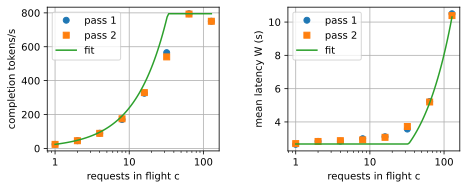

In [26]:
def fit(table):
    """W_0, X_max, c* and the knee: the smallest level from which on the
    efficiency X W_0 / c stays below 0.7."""
    table = table.sort_values('c')
    W_0, X_max = table.W[table.c == 1].median(), table.X.max()
    E = (table.X * W_0 / table.c).to_numpy()
    knee = next((c for i, c in enumerate(table.c) if (E[i:] < 0.7).all()),
                None)
    return W_0, X_max, X_max * W_0, knee

knees = []
for p, table in sweep.groupby('pass'):
    W_0, X_max, c_star, knee = fit(table)
    knees.append(knee)
    print(f'pass {p}: W_0 {W_0:.2f} s, X_max {X_max:.1f} requests/s, '
          f'c* {c_star:.1f}, efficiency below 0.7 from c = {knee}')
both = knees[0] is not None and knees[0] == knees[1]
print('knee in both passes:', 'yes' if both else 'no')
assert both, "no knee common to both passes: set the server's batch cap"
W_0, X_max, _, _ = fit(sweep)  # pooled, for the fitted curves
tokens = (sweep.X_tokens / sweep.X).mean()  # completion tokens per request
grid = np.geomspace(1, max(LEVELS), 100)
passes = [sweep[sweep['pass'] == p] for p in (1, 2)]
fig, axes = d2l.plt.subplots(1, 2, figsize=(7.4, 2.6),
                             gridspec_kw={'wspace': 0.4})
d2l.plot([t.c.to_numpy() for t in passes] + [grid],
         [t.X_tokens.to_numpy() for t in passes] +
         [np.minimum(grid / W_0, X_max) * tokens], 'requests in flight c',
         'completion tokens/s', legend=['pass 1', 'pass 2', 'fit'],
         xscale='log', fmts=('o', 's', '-'), axes=axes[0])
d2l.plot([t.c.to_numpy() for t in passes] + [grid],
         [t.W.to_numpy() for t in passes] + [np.maximum(W_0, grid / X_max)],
         'requests in flight c', 'mean latency W (s)',
         legend=['pass 1', 'pass 2', 'fit'], xscale='log',
         fmts=('o', 's', '-'), axes=axes[1])

<!-- d2l:prose id=api-md-28 fw=all -->

Both passes give $W_0 \approx 2.7$ s and $X_{\max} \approx 12.4$ requests
per second, so the two straight lines of the equation meet at
$c^* \approx 33$. The efficiency rule names $c = 64$, again in both passes.
The two statements agree: the corner lies just above 32, and 64 is the first
level of our grid that is clearly past it.

But did the server not decode 45 sequences at once? It did, and 33 and 45
are one capacity, computed with two different times. The model assumes that
a request in a full batch is as fast as a request alone. It is not: a
sequence in the full batch decodes for about 3.7 s, and 12.4 requests per
second times 3.7 s gives the 46 sequences of the table, where 12.4 times the
unloaded 2.7 s gave 33. The latency starts to grow long before the cache is
full.

The plot shows the two passes with the fitted curves, the throughput in
tokens per second on the left and the mean latency on the right. The fit is
good at both ends and too sharp in the middle: at $c = 32$ the server
delivers about 550 tokens per second where the model promises more than 750.
Real servers round the corner.

What should a client of this server do? Raising $c$ from 32 to 64 still adds
more than 40% to the throughput, while the mean latency grows from about
3.6 s to 5.2 s. Beyond 64 nothing is gained but waiting. A client that wants
throughput keeps about 64 requests in flight, and one that wants short waits
stays near 32.

Does a hosted provider have a knee as well? Surely, but one client will not
find it. We run three levels of the same loop against the flagship.

In [27]:
contrast = rec.hosted(FLAGSHIP, rec.cache('lm-api-sweep-v1', 'flagship'),
                      share=0.1, reasoning={'enabled': False})
first, rows = 4084, []  # train items after the local sweep's
for c in (1, 8, 32):
    rows.append(await closed_loop(contrast, c, first, **SWEEP))
    first += 8 * c
hosted_sweep = pd.DataFrame(rows)
check_little(hosted_sweep, 0.10, 0.05)
X_c = hosted_sweep.set_index('c').X
print(f'X(32) / X(1) = {X_c[32] / X_c[1]:.1f}')
show(hosted_sweep)

X(32) / X(1) = 30.2
 c     X X_tokens     W  ttft_p50  ttft_p90 in decode  little  sustained
 1  0.70       45 1.417     1.067     1.350       0.3   0.996      0.996
 8  5.63      360 1.333     0.982     1.168       2.0   0.937      0.997
32 21.23     1359 1.445     1.032     1.247       8.4   0.959      0.996
no 429s, retries or failed requests at any level


<!-- d2l:prose id=api-md-29 fw=all -->

The throughput at 32 requests in flight is about 30 times that at 1, the
latency stays at about 1.4 s, and no level drew a 429. The check ratio
`little` drops to about 0.95 at the two higher levels. Hosted latencies vary
more than local ones, so the requests wholly inside the window are the
shorter ones, the effect that we described. We are far below this provider's
knee, so the 21 requests per second are a lower bound on its capacity and
nothing more. Most of the 1.4 s is the wait for the first token, about 1 s,
which is why a time to first token should be reported apart from the latency
of a whole response. One more caution for anyone who times a stream: chunks
are not tokens. A provider may pack several tokens into one chunk, so a
token rate must come from `usage`.

## Accuracy, Cost and Reproducibility

### Hosted and Local Models on GSM8K

Experiment 2 asks the question that a user of these services faces: which
model, at what price? We take the 100 GSM8K test problems of
that section and send every model the same request. It opens
with four worked examples as alternating user and assistant turns, built by
`d2l.fewshot_prompt` of that section, followed by the
question. We decode at temperature 0 with seed 0, at most 512 tokens and
reasoning off.

Each example ends on a line of the form `#### answer`, the format that
`d2l.extract_answer` looks for first. Where a reply has no such line, the
extractor falls back on the last number in it. One model, sent the 100
requests once, is an *arm* of the experiment. The prompt, the decoding
settings and the extractor are the same for every arm. What differs is the
model, and that includes how well it follows the format of its examples.

In [28]:
GSM_DEMOS = [(q, re.sub(r'<<[^>]*>>', '', a))  # calculator notes removed
             for q, a in zip(gsm_train.question[:4], gsm_train.answer[:4])]
GSM_MESSAGES = [d2l.fewshot_prompt(GSM_DEMOS, gsm_test.question[i],
                                   template='chat_multi') for i in GSM_IDS]
GSM_GOLD = [d2l.extract_answer(gsm_test.answer[i]) for i in GSM_IDS]
GSM_PARAMS = {'temperature': 0, 'seed': 0, 'max_tokens': 512}
for m in GSM_MESSAGES[0]:
    print(f'{m["role"]:9s} {m["content"][:64]!r}')
print('parameters:', GSM_PARAMS)
print('thinking off: reasoning.enabled=False (router), '
      'enable_thinking=False (local)')

user      'Natalia sold clips to 48 of her friends in April, and then she s'
assistant 'Natalia sold 48/2 = 24 clips in May.\nNatalia sold 48+24 = 72 cli'
user      'Weng earns $12 an hour for babysitting. Yesterday, she just did '
assistant 'Weng earns 12/60 = $0.2 per minute.\nWorking 50 minutes, she earn'
user      'Betty is saving money for a new wallet which costs $100. Betty h'
assistant "In the beginning, Betty has only 100 / 2 = $50.\nBetty's grandpar"
user      'Julie is reading a 120-page book. Yesterday, she was able to rea'
assistant 'Maila read 12 x 2 = 24 pages today.\nSo she was able to read a to'
user      'Carmen has $100, Samantha has $25 more than Carmen, and Daisy ha'
parameters: {'temperature': 0, 'seed': 0, 'max_tokens': 512}
thinking off: reasoning.enabled=False (router), enable_thinking=False (local)


<!-- d2l:prose id=api-md-30 fw=all -->

There are four arms. The flagship runs twice, as replicas 0 and 1 of
identical requests. The second run costs little and gives what no single run
can: the disagreement of a model with itself, the floor below which no
difference between models means anything. Qwen3.8-27B and the local Qwen3-4B
complete the set, each arm with eight requests in flight.

In [29]:
gsm_flagship = rec.hosted(FLAGSHIP, rec.cache('lm-api-gsm8k-v1', 'flagship'),
                          share=0.2, reasoning={'enabled': False})
gsm_second = rec.hosted(SECOND, rec.cache('lm-api-gsm8k-v1', 'second'),
                        share=0.2, reasoning={'enabled': False})
gsm_local = local(rec.cache('lm-api-gsm8k-v1', 'local'))
ARMS = {'flagship r0': (gsm_flagship, 0, 8),
        'flagship r1': (gsm_flagship, 1, 8),
        'Qwen3.8-27B': (gsm_second, 0, 8),
        'Qwen3-4B local': (gsm_local, 0, 8 if LOCAL_BATCHES else 1)}
outs = await asyncio.gather(*(chat_batch(api, [
    {'messages': m, 'replica': k, **GSM_PARAMS} for m in GSM_MESSAGES],
    concurrency=c) for api, k, c in ARMS.values()))
RESULTS, CORRECT, rows = dict(zip(ARMS, outs)), {}, []
for arm, results in RESULTS.items():
    assert not any(isinstance(r, Exception) for r in results), arm
    assert not any(d2l.chat_thinks(r) for r in results), f'{arm}: thinking'
    correct = np.array([d2l.extract_answer(r.text) == g
                        for r, g in zip(results, GSM_GOLD)], dtype=float)
    CORRECT[arm], ci = correct, d2l.bootstrap_ci(correct)
    p50, p90 = np.percentile([r.t_total for r in results], [50, 90])
    rows.append({'arm': arm, 'concurrency': ARMS[arm][2],
                 'accuracy': ci.mean, 'lo': ci.ci[0], 'hi': ci.ci[1],
                 'prompt tokens': np.mean([r.usage['prompt_tokens']
                                           for r in results]),
                 'completion tokens': np.mean([r.usage['completion_tokens']
                                               for r in results]),
                 'p50 s': p50, 'p90 s': p90})
gsm = pd.DataFrame(rows).set_index('arm')
print(gsm.to_string(formatters={
    'prompt tokens': '{:.0f}'.format, 'completion tokens': '{:.0f}'.format,
    'p50 s': '{:.1f}'.format, 'p90 s': '{:.1f}'.format},
    float_format='{:.2f}'.format))

                concurrency  accuracy   lo   hi prompt tokens completion tokens p50 s p90 s
arm                                                                                        
flagship r0               8      0.97 0.93 1.00           462               104   1.4   2.1
flagship r1               8      0.97 0.93 1.00           462                98   1.5   2.1
Qwen3.8-27B               8      0.94 0.89 0.98           566               172   2.0   5.3
Qwen3-4B local            8      0.83 0.75 0.90           540               182   7.6  12.9


<!-- d2l:prose id=api-md-31 fw=all -->

The flagship solves 97 of the 100 problems in both replicas, Qwen3.8-27B
solves 94, and the local Qwen3-4B 83, each with a bootstrap interval several
points wide. The flagship is also the fastest, at about a second and a half
per problem in the median.

The reasoning trap taught us to ask how a reply ended before we count it as
wrong. The table does not say, so we looked in the recorded responses. Three
hosted replies ran into the limit of 512 tokens and count as errors: one of
the flagship's first run, on a problem that its second run solved in about
100 tokens, and two of Qwen3.8-27B's, among them the problem that this model
solved earlier in this section with a budget of 1,024. These replies ran out
of budget, which is not the same as wrong arithmetic. Three of them are too
few to change any verdict below.

Not every reply copied the format of its examples. Many end on a boxed or a
bold number, those of the local model most often, and for these the fallback
of the extractor finds the answer.

Note the token columns. The same messages are 462 prompt tokens for one
model and 566 for another, since each has its own tokenizer and template,
and the replies of one model are nearly twice as long as those of another.
Tokens cannot be compared across models, and neither can a price per token.
The quantity to compare is the price of a correct answer: the cost of an
arm divided by the number of problems that it solved. For the local arm the
currency is GPU time.

In [30]:
rows = []
for arm, (api, _, _) in ARMS.items():
    results, n_correct = RESULTS[arm], max(CORRECT[arm].sum(), 1)
    if api.price is not None:  # hosted: dollars, billed and at list price
        cost = sum(usd(api, r) for r in results)
        listed = sum(d2l.api_cost({**r.usage, 'cached_tokens': 0}, api.price)
                     for r in results)  # as if no prompt token were cached
        cached = sum(r.usage.get('cached_tokens') or 0 for r in results)
        rows.append({'arm': arm, 'cached share': cached / sum(
                         r.usage['prompt_tokens'] for r in results),
                     'USD per 100': 100 * cost / len(results),
                     'USD per 1,000 correct': 1000 * cost / n_correct,
                     'at list price': 1000 * listed / n_correct})
    else:  # local: the arm's wall-clock span on one GPU
        span = (max(r.t_send + r.t_total for r in results) -
                min(r.t_send for r in results))
        rows.append({'arm': arm, 'GPU-s per correct': span / n_correct})
cost = pd.DataFrame(rows).set_index('arm')
ratio = cost.loc['Qwen3.8-27B'] / cost.loc['flagship r0']
print(f'Qwen3.8-27B / flagship: accuracy x '
      f'{gsm.accuracy["Qwen3.8-27B"] / gsm.accuracy["flagship r0"]:.2f}; '
      f'USD per correct x {ratio["USD per 1,000 correct"]:.2f} billed, '
      f'x {ratio["at list price"]:.2f} at list price')
print(cost.to_string(na_rep='-', formatters={
    'cached share': '{:.2f}'.format, 'USD per 100': '{:.4f}'.format,
    'USD per 1,000 correct': '{:.3f}'.format,
    'at list price': '{:.3f}'.format, 'GPU-s per correct': '{:.2f}'.format}))

Qwen3.8-27B / flagship: accuracy x 0.97; USD per correct x 6.07 billed, x 3.66 at list price
               cached share USD per 100 USD per 1,000 correct at list price GPU-s per correct
arm                                                                                          
flagship r0            0.77      0.0087                 0.090         0.149                 -
flagship r1            0.78      0.0083                 0.086         0.145                 -
Qwen3.8-27B            0.00      0.0513                 0.546         0.546                 -
Qwen3-4B local            -           -                     -             -              1.33


<!-- d2l:prose id=api-md-32 fw=all -->

A hundred problems cost less than a cent on the flagship and about five
cents on Qwen3.8-27B. Per correct answer the smaller model is about six
times as expensive as billed and still almost four times at list prices,
while the accuracies differ by three points. Part of the gap is the price
list: Parasail's price for output tokens is more than three times Novita's.
Part is the model, since Qwen3.8-27B writes longer replies. The rest is a
discount. Novita billed about three quarters of the flagship's prompt
tokens, the four examples that open every request, at its cached rate.
Parasail's row in the listing shows a cached price too, and in our run it
cached nothing.

The size of a model is a poor guide to its price. Here the model with about
27 times the parameters is the cheaper one per correct answer. One reason
is its architecture. The flagship is a sparse *mixture of experts*: in
every layer it holds several hundred expert sub-networks and sends each
token through a handful of them, so most of its parameters do no work on
any given token. The parameter count tells a provider how much memory to
hold, and much less about the computation that a token costs.

The local model gets its price from the GPU. It needs about 1.3 GPU-seconds
per correct answer with eight requests in flight, which is 0.37 GPU-hours
for 1,000 correct answers. In November 2026 an RTX 4090, the 24 GB card that
we used, rented for 0.30 to 0.50 dollars an hour
(the table), so the 1,000 answers cost between 10 and 20
cents. That is more than the flagship's 9 cents, and it is the price of the
least accurate of the three models. A small model on a card of our own is
not automatically the cheap option.

Its price depends on how busy we keep the card. With eight requests in
flight, the server of Experiment 1 delivered less than a quarter of the
tokens per second that it reached with 64. If this experiment could fill the
server as well as that one did, the same 1,000 answers would cost 2 to 4
cents, less than half the flagship's price. This is an estimate and not a
measurement: we did not run that arm, and the longer prompts of this
experiment take more of the cache per request. Either way, what a local
answer costs is decided by how full we keep the server, and here that moves
the price from well below the flagship's to twice as much. Exercise
6 derives the rental prices at which the
comparison turns.

Are these differences real at 100 problems? Three tools come from
that section. All arms answered the same problems, so we
compare two arms problem by problem, and the difference in accuracy gets a
paired bootstrap interval. The *discordant* problems are those that one arm
solved and the other did not. The table counts them in the column `b` (only
the first arm solved the problem) and the column `c` (only the second; this
`c` is not the concurrency). The minimum detectable effect (`MDE`) is the
smallest true difference that a sample of this size would detect with 80%
power.

Two tools are new, and both are needed because the sample is small. With a
handful of discordant problems no normal approximation can be trusted, so we
use the exact *McNemar test*. If two arms were equally accurate, each
discordant problem would fall to either side with probability one half, and
the test computes the binomial probability of a split at least as uneven as
the one observed. Moreover, three comparisons on the same 100 problems give
chance three opportunities. *Holm's method* adjusts for that: it multiplies
the smallest of the three $p$-values by three and the next by two.

A difference counts as resolved only if its adjusted $p$-value is below 0.05
and its interval excludes zero. We ask for both because the test and the
bootstrap interval are two different approximations, which can disagree on
so few discordant problems, and we believe a difference only when neither
objects. The fourth row is the noise floor, replica 0 against replica 1.
Read `difference`, the interval and the counts `b` and `c` first, and the
verdict last.

In [31]:
def holm(p):  # Holm's step-down adjustment of p-values
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted

PAIRS = {'flagship - 27B': ('flagship r0', 'Qwen3.8-27B'),
         'flagship - local': ('flagship r0', 'Qwen3-4B local'),
         '27B - local': ('Qwen3.8-27B', 'Qwen3-4B local'),
         'r0 - r1': ('flagship r0', 'flagship r1')}  # the noise floor
rows = []
for name, (a, b) in PAIRS.items():
    x, y = CORRECT[a], CORRECT[b]
    res = d2l.paired_bootstrap(x, y, n_boot=10000, seed=0)
    n_ab, n_ba = int((x > y).sum()), int((x < y).sum())  # discordant
    p = (stats.binomtest(min(n_ab, n_ba), n_ab + n_ba, 0.5).pvalue
         if n_ab + n_ba else 1.0)
    rows.append({'comparison': name, 'difference': res.mean,
                 'lo': res.ci[0], 'hi': res.ci[1], 'b': n_ab, 'c': n_ba,
                 'McNemar p': p, 'MDE': d2l.min_detectable_effect(
                     np.std(x - y, ddof=1), len(x))})
compare = pd.DataFrame(rows)
compare['Holm p'] = list(holm(compare['McNemar p'][:3].to_numpy())) + [None]
floor = compare.iloc[3]
if floor.lo > 0 or floor.hi < 0:
    print('replicas disagree systematically: no verdicts')
else:
    compare['verdict'] = [
        'resolved' if h < 0.05 and (lo > 0 or hi < 0)
        else 'unresolved at n = 100' for h, lo, hi in zip(
            compare['Holm p'][:3], compare.lo[:3], compare.hi[:3])] + [
        'noise floor']
print(compare.to_string(index=False, na_rep='', formatters={
    'difference': '{:.2f}'.format, 'lo': '{:.2f}'.format,
    'hi': '{:.2f}'.format, 'McNemar p': '{:.4f}'.format,
    'MDE': '{:.2f}'.format, 'Holm p': '{:.4f}'.format}))

      comparison difference    lo   hi  b  c McNemar p  MDE Holm p               verdict
  flagship - 27B       0.03 -0.01 0.08  4  1    0.3750 0.06 0.3750 unresolved at n = 100
flagship - local       0.14  0.07 0.22 15  1    0.0005 0.11 0.0016              resolved
     27B - local       0.11  0.05 0.18 12  1    0.0034 0.10 0.0068              resolved
         r0 - r1       0.00 -0.03 0.03  1  1    1.0000 0.04                  noise floor


<!-- d2l:prose id=api-md-33 fw=all -->

The two replicas of the flagship differ on two problems, one in each
direction: identical requests at temperature 0 did not give identical
outcomes. One of the two is the reply that the limit of 512 tokens cut short
in the first run. Against this floor, a difference of 0.00 with an interval
of $[-0.03, 0.03]$, the three points between the flagship and Qwen3.8-27B
are unresolved. Five discordant problems split four to one, the interval
$[-0.01, 0.08]$ includes zero, and the minimum detectable effect is about
six points. In fact no split of five problems could have passed the test,
since even five to none has a $p$-value of $2/32 \approx 0.06$. We cannot
say from this experiment which of the two models is more accurate, and the
comparison rests on the price of a correct answer.

Both differences to the local model are resolved, 14 points $[0.07, 0.22]$
and 11 points $[0.05, 0.18]$. One caution carries over from
that section. GSM8K has been public for years and
may be in the training data of every one of these models, so the scores
order the models on these 100 problems and say nothing absolute about their
arithmetic.

### Determinism and Model Identity

The two replicas raise a question that Experiment 3 asks directly. We send
the same request many times, at temperature 0 and with a fixed seed, and
count the different replies. The field test found that the flagship's
provider gives no repeatable draw for a seed. At temperature 0 that should
not matter, since nothing is drawn: the model emits the token with the
largest logit. What the experiment asks is whether the largest logit itself
is stable.

The requests are the 4-shot prompts of three problems, those of our 100 with
the longest reference solutions. Long solutions make long replies, and every
token of a reply is one more place where two candidates can nearly tie. The
flagship receives each request 20 times. The local server receives each of
them five times in sequence with nothing else running, and five more times
while eight other clients keep it busy.

In [32]:
DET_IDS = LONGEST[:3]  # the longest reference solutions
DET_MESSAGES = [GSM_MESSAGES[GSM_IDS.index(i)] for i in DET_IDS]

def replicas(first, n):  # n replicas of each of the three requests
    return [{'messages': m, 'replica': k, **GSM_PARAMS}
            for m in DET_MESSAGES for k in range(first, first + n)]

N_LOCAL = 5  # 30 local replies of 13-18 s stay inside the 30-min target
det_flagship = rec.hosted(FLAGSHIP, rec.cache('lm-api-determinism-v1',
                                              'flagship'),
                          share=0.1, reasoning={'enabled': False})
det_local = local(rec.cache('lm-api-determinism-v1', 'local'))
on_flagship, alone = await asyncio.gather(
    chat_batch(det_flagship, replicas(0, 20), concurrency=4),
    chat_batch(det_local, replicas(0, N_LOCAL), concurrency=1))
BACKGROUND = [i for i in range(len(gsm_test)) if i not in GSM_IDS][:64]
LANES = 8 if LOCAL_BATCHES else 1  # more would queue at a serial server
print(f'under load: {LANES} background lane(s); the local server '
      f'{"batches" if LOCAL_BATCHES else "runs one request at a time"}')

def background(j):  # request j of the load: 64 other problems, cycled
    return {'messages': d2l.fewshot_prompt(GSM_DEMOS, gsm_test.question[
        BACKGROUND[j % 64]], template='chat_multi'), 'replica': j // 64,
            **GSM_PARAMS}

load = (d2l.BackgroundLoad(local(rec.cache('lm-api-determinism-v1',
                                           'background'), mode='live'),
                           background, LANES)
        if LOCAL_LIVE else contextlib.nullcontext())
async with load:  # the load's responses are logged, never replayed
    under_load = await chat_batch(det_local, replicas(100, N_LOCAL),
                                  concurrency=1)
if LOCAL_LIVE:
    print(f'background: {len(load.failures)} failed requests')

under load: 8 background lane(s); the local server batches


<!-- d2l:prose id=api-md-34 fw=all -->

For each problem and condition the next cell counts the distinct replies,
the character at which a reply first departs from the most common one, and
the distinct final answers.

In [33]:
rows = []
for condition, results in (('flagship', on_flagship), ('local alone', alone),
                           ('local under load', under_load)):
    assert not any(isinstance(r, Exception) or d2l.chat_thinks(r)
                   for r in results)
    n = len(results) // len(DET_IDS)  # replicas per problem
    for k, i in enumerate(DET_IDS):
        texts = [r.text for r in results[n * k:n * k + n]]
        modal = collections.Counter(texts).most_common(1)[0][0]
        firsts = [len(os.path.commonprefix([t, modal]))  # in characters
                  for t in texts if t != modal]
        rows.append({'condition': condition, 'problem': i, 'replicas': n,
                     'distinct': len(set(texts)),
                     'diverges at (min)': min(firsts, default=None),
                     '(median)': np.median(firsts) if firsts else None,
                     'answers': len({d2l.extract_answer(t) for t in texts})})
print(pd.DataFrame(rows).to_string(index=False, na_rep='-', formatters={
    'diverges at (min)': '{:.0f}'.format, '(median)': '{:g}'.format}))

       condition  problem  replicas  distinct diverges at (min) (median)  answers
        flagship      409        20         6                99       99        1
        flagship      422        20         5                 0       95        1
        flagship      601        20         7                12       20        1
     local alone      409         5         2               240      240        1
     local alone      422         5         1                 -        -        1
     local alone      601         5         2                80       80        1
local under load      409         5         5                34      107        2
local under load      422         5         5               144    222.5        1
local under load      601         5         5                12       45        3


<!-- d2l:prose id=api-md-35 fw=all -->

Twenty identical requests to the flagship return five to seven different
texts. They part ways within the first hundred characters, on one problem at
the very first, and all reach the same final answer.

How can a model that draws nothing give different replies? The mechanism is
the one that moved our own scores with the batch size in
that section. Floating-point addition is not
associative, so the same sum taken in a different order differs in its last
bits. A serving engine batches whatever requests happen to be in flight, and
its kernels choose the order of their reductions by the shape of the batch.
The logits of our request therefore depend on who else is being served
[@He.2025]. The smallest change flips a near-tie between two tokens,
and from that token on the texts diverge. The seed is beside the point.

The surprise is the local server, where we chose the seed and nothing else
was running: on two of the three problems the five replies are not all equal
either. No other client changed the batch here. What changed the order of
the sums is the cache. Continuous batching shares the stored keys and values
of a common prompt prefix between requests. The first request computes the
prompt, and the later ones reuse its cached blocks, which is another
sequence of operations with other last bits. We checked this cause. A field
of Transformers' `ContinuousBatchingConfig`, which `transformers serve` does
not expose, switches prefix sharing off, and then the five replies agree.

Under load every reply is different, and now the answers differ too: two
distinct answers on one problem and three on another. Whether a problem
counts as solved then depends on what else the server was doing at the time.
This reaches back to Experiment 2, whose local arm ran with eight requests
in flight. Its score of 83 is one draw. The gaps of 11 and 14 points to the
hosted models are far above any floor that we saw, but we measured that
floor for the flagship only.

A seed promises reproducibility only for a sampler and kernels that we
control, and behind an API we control neither.
that section shows what it takes to make
inference repeatable. Note also what would not have been evidence. Had all
60 hosted replies been identical, that would not have shown determinism,
only that no near-tie happened to flip.

A second kind of drift is slower. The string that we send as `model` names
an entry of a listing, not a set of weights. We used an identifier with a
date in it, since an undated alias may be pointed at a newer release at any
time. One set of weights is served by many providers at precisions from 4 to
16 bits, and by default a router spreads requests over them by price and
load. An experiment that does not pin its provider may therefore compare a
model with a differently quantized copy of itself.

Whether a provider serves the weights that it names is a statistical
question that a client can ask. @Gao.Liang.Guestrin.2025 compared
samples from 31 commercial endpoints with samples from the released weights
by a two-sample test, and for 11 of them the two distributions differed.
@Cai.Shi.Zhao.ea.2025 show that such tests are hard to make reliable
against a provider that wants to hide a substitution. Our client does the
least that can be done, and records the served model and the provider with
every response.

That ends the experiments, and the local server is stopped.

In [34]:
if server is not None:
    print('server exit code', server.stop())
else:
    print('no local server in replay')

no local server in replay


<!-- d2l:prose id=api-md-36 fw=all -->

The last cell adds up the logs of all clients: live calls, retries, 429s and
dollars per cache, the served model and the provider of every arm, and a
reconciliation of the bill.

In [35]:
rows, ids = [], set()
for api in {api.calls_path: api for api in rec.clients}.values():
    t = d2l.api_recorded(api)  # totals of every session of the recording
    key = next((k for k in API_SHA1 if k in api.cache_path), 'scratch')
    arm = os.path.splitext(os.path.basename(api.cache_path))[0]
    rows.append({'cache': key.replace('lm-api-', '') + '/' + arm,
                 **{k: t.get(k, 0) for k in (
                     'live calls', 'retries', '429s', 'failed', 'USD',
                     'usage cost', 'listing cost')}})
    if api.price is not None:  # one provider and one served id per arm
        assert len(t['served']) <= 1 and len(t['providers']) <= 1, t
    ids.update((re.sub(r'@([0-9a-f]{8})[0-9a-f]+', r'@\1', s),
                'local' if p == 'None' else p)
               for s, p in zip(t['served'], t['providers']))
manifest = pd.DataFrame(rows)
spent = sum(api.spent_usd for api in rec.clients)  # this run's live calls
total = manifest.USD.sum()  # every session of the recording
assert spent <= COST_CAP_USD and total <= COST_CAP_USD, (spent, total)
reported = manifest['usage cost'].sum()  # where the provider sent a cost
if reported:
    print('cost from the listing / cost the provider reported: '
          f'{manifest["listing cost"].sum() / reported:.4f}')
if API_MODE != 'replay':  # sessions accumulate in each artifact's manifest
    d2l.write_api_manifests(rec.clients, RECORD_DIR)
if os.environ.get('OPENROUTER_API_KEY'):  # in no cache, log or manifest
    n = d2l.assert_key_absent([RECORD_DIR, os.path.join(
        D2L_API_LOG_DIR, 'scratch')], os.environ['OPENROUTER_API_KEY'])
    print(f'key material: none in {n} files')
print(f'clients of this notebook: {manifest["live calls"].sum()} live '
      f'calls, {total:.4f} USD of {COST_CAP_USD}; this run {spent:.4f} USD')
committed = d2l.api_committed([rec.folder(k) for k in API_SHA1])
print(f'committed caches: {committed["live calls"]} live calls, '
      f'{committed["USD"]:.4f} USD, openai SDK {", ".join(committed["sdk"])}')
print('(the background lanes and the local probe included, the '
      'closed-model probe not)')
for s, p in sorted(ids):
    print(f'served id {s} by {p}')
print(manifest.drop(columns=['usage cost', 'listing cost']).to_string(
    index=False, formatters={'USD': '{:.6f}'.format}))

cost from the listing / cost the provider reported: 1.0000
clients of this notebook: 4950 live calls, 0.1023 USD of 5.0; this run 0.0000 USD
committed caches: 5184 live calls, 0.1023 USD, openai SDK 3.49.0
(the background lanes and the local probe included, the closed-model probe not)
served id Qwen/Qwen3-4B@1cfa9a72 by local
served id deepseek/deepseek-v4.1-flash-1017 by Novita
served id qwen/qwen3.8-27b by Parasail
                  cache  live calls  retries  429s  failed      USD
      probe-v2/flagship          17        0     0       0 0.000484
        probe-v2/second          20        7     7       7 0.004832
     effort-v1/flagship          15        0     0       0 0.004169
         sweep-v1/local        4080        0     0       0 0.000000
      sweep-v1/flagship         328        0     0       0 0.017266
      gsm8k-v1/flagship         200        0     0       0 0.017025
        gsm8k-v1/second         100        0     0       0 0.051318
         gsm8k-v1/local         100

<!-- d2l:prose id=api-md-37 fw=all -->

The committed recording, about 740 paid requests, cost about ten cents. The
cost computed from the listing equals the cost that the router reported, to
four digits. The router bills by its listing, then, and `d2l.api_cost`
computes the equation as the router does. A provider's own
invoice is not part of this check. Each arm was served by one provider under
one model identifier, as the pins demanded.

The remaining numbers are for a reader who audits the recording. The clients
of this page made 4,950 live calls, most of them to our own server. The
committed recording holds 5,184, since it also contains the background load
of Experiment 3 and the field test of the local server. It leaves out the
test of the closed model. The seven 429s all came from Parasail. The column
`failed` counts failed attempts and not failed requests: the client retried
each of the seven, and no request was lost.

## Limits of a Hosted Model

Everything that the three experiments measured came through the protocol.
Two kinds of limit remain: what we may do with the replies, and what no
reply contains.

### Licenses and Terms of Service

The first limit is not technical. A prompt that is sent to a service leaves
our machine, and the reply comes back under somebody's terms. Two documents
govern every call: the license of the weights, and the terms of service of
whoever runs them. the table records what these documents
say about the responses that we stored with the book's data.

<!-- tbl-caption:Licenses and terms of service behind the recorded responses. We read the licenses on 14 November 2026 and the terms of service on 18 November 2026. Terms change; the dates in the table are those printed on the documents. -->

| Document | What it says | Consequence here |
|---|---|---|
| MIT license of the DeepSeek-V4.1-Flash weights | use, copying and redistribution permitted with the notice | responses stored with attribution |
| Apache-2.0 license of the Qwen3.8-27B and Qwen3-4B weights | use and redistribution permitted with the notice | responses stored with attribution |
| OpenRouter terms of service (updated 31 August 2026) | inputs are not stored unless the account opts in to prompt logging; the user agrees to the terms that apply to each model, and rights in an output follow those terms | the router adds no rights of its own, so we read the license of each model and the terms of its provider |
| Novita terms of service (updated 5 August 2026) | by default, customer content is not used to train Novita's models and is not kept once the output is delivered; we found no clause on training with outputs or on publishing measurements | responses stored for replay |
| Parasail terms of service (dated 10 November 2025) | customer content is not used to train Parasail's models; the customer owns inputs and outputs; content available through the platform may not be used to train or develop machine learning models; performance information about the platform may not be disclosed publicly | responses stored for replay only, never used as training data |

The table has no row for the closed model, whose replies are not in the
book's data at all: we kept only the verdicts of the field test.

The two provider rows differ, and that is the reason to read them. The
Parasail row shows why the second document matters even when the first is
permissive. Apache-2.0 would let us train on the outputs of Qwen3.8-27B.
Whether the service that produced them allows the same is a separate
question, and the clause in the table suggests that it does not.

The last clause of that row is easy to overlook, and it concerns
measurements like ours: the customer may not "publicly disclose to any third
party any performance information or analysis relating to the Platform". The
latency and the rate limits of a named provider are performance information,
and this section prints both for Parasail. We read the clause only after the
recording had been made, which is the wrong order. Our requests reached
Parasail through the router's account and not through one of our own, and
how the clause applies to such requests is for the provider to say. Whoever
plans to publish numbers of this kind should look for such a clause before
the first request, and ask.

Later chapters let hosted models write questions and training examples.
Before any of them does, we read both documents and record the answer with
the data. And whatever the terms say, a prompt is disclosed to the provider
the moment it is sent, so we send only public data, here the questions of
GSM8K.

### Quantities the Protocol Withholds

The other limits are technical. Let us go back through the chapter and ask,
method by method, what a client can still obtain. the figure
does so for four kinds of endpoint, from weights that run in the book's own
code to a closed model behind a router.

![What each kind of endpoint gives a client. The rows are the quantities and controls that the methods of this chapter relied on. A filled circle marks what is available, a half circle what depends on the provider or the server, and an open circle what a client does not get.](../img/mdl-lm-pretrained-api-lost.svg)

Start with the log-probabilities. The chat-completions protocol has no field
for the log-probabilities of a prompt. None of the four endpoints that we
tested returned them, although some servers add such a field of their own.
Scoring answer options, cloze scoring and bits per byte
(that section) all need these log-probabilities, so behind an
API an evaluation falls back on generating text and extracting an answer, as
in Experiment 2. Log-probabilities of generated tokens come only where the
provider returns them, and our field test found one provider that returned
them for part of a reply.

Weights and activations are gone, and with them everything of
that section: one cannot patch an activation that one
cannot read. The prompt is rendered on the server, and the sampler is
whatever subset of fields the provider honours. The row on seeds and
batching needs a remark. The protocol does have a `seed` field, and the
figure still shows an open circle for the hosted models, because no hosted
endpoint returned a repeatable draw for it. For the batch there is no field
at all. It is the provider's business, which is why Experiment 3 came out as
it did.

What survives is text, the `usage` block, structured output where the
provider enforces a schema, and as many samples as one is willing to pay
for, drawn by repeated requests, since no endpoint honoured `n=2`. That is
enough for accuracy with error bars, cost, latency and throughput, the
measurements of this section. It is not enough to check a port layer by
layer, to score a given continuation, or to test a claim about a mechanism.

For those we need the weights, and so the rest of this part works with
models that we hold. The first thing that we shall ask of them is something
that no chat endpoint returns at all: a vector for each text, which a system
that retrieves documents needs. That is the subject of
that section.

## Summary

A hosted model is a service that a client can measure. The chat-completions
protocol returns text and a `usage` block, and a client that stores every
response under a hash of everything that can change it makes its
measurements replayable. Little's law, $XW = c$ in a closed loop, turns two
timestamps per request into throughput, latency and the knee beyond which
more concurrency only adds waiting. From `usage` and a dated price follow
the cost of a response and the price of a correct answer, which separated
two hosted models that accuracy on 100 problems could not. The service
itself is not deterministic: identical requests at temperature 0 returned
different texts from a hosted endpoint and from our own server. The protocol
has no place for the log-probabilities of a prompt, for activations or for
weights, so scoring by likelihood, layer-wise checks and interventions
cannot be done through it.

## Exercises

1. **A detection rule of your own.** The field test trusted a request field
   only after a rule had seen its effect.
    1. Write a detection rule for `max_tokens` in the style of
       `seed_honoured`. Which request does it send, and which parts of the
       response does it compare?
    1. Describe two responses that a careless rule would wrongly call
       honoured: one from a reply that is short of its own accord, and one
       like that of the closed model in the field test, whose `usage`
       reported more reasoning tokens than completion tokens under its cap.
       Change your rule so that it excludes both.
    1. Write a rule for `top_p`. Why does it need a control request, as the
       rule for `seed` needed the request with seed 8?

1. [code] **The contents of the request hash.** The demonstration in the
   text settled five changes to a request. Consider three more: the order
   of the keys in its parameters, `max_tokens`, and the port of the base
   URL.
    1. For each change, decide whether the hash must change, and give the
       reason in one sentence. Verify your answers with `d2l.request_hash`.
    1. The hash contains the hostname and not the port. Describe an
       experiment that this choice makes possible, and a situation in which
       it would return a wrong cache entry.

1. [code] **Equal jitter.** Equal jitter sleeps for
   $d_a/2 + U$ with $U$ uniform on $[0, d_a/2]$.
    1. Derive the mean and the variance of this sleep and compare them
       with those of full jitter. Which schedule spreads clients that
       failed together more widely?
    1. Add equal jitter to `retry_storm` and compare the finish time and
       the number of attempts of the three schedules over 200 seeds.
       Explain the order of the finish times from the first sub-problem.

1. **The closed loop beyond the knee.** Consider the model of a closed
   loop in the equation.
    1. Show that the efficiency $E(c) = X W_0 / c$ equals
       $\min(1, c^*/c)$. At which $c$ does it cross 0.7? With levels at the
       powers of two and $c^* = 33$, which is the first level whose
       efficiency is below 0.7?
    1. Compute $E(32)$ for both passes of Experiment 1 from the printed
       table. The model predicts a value close to 1. Which of its two
       assumptions fails below the knee, and which column shows it?
    1. Our client keeps the number of requests in flight fixed. In an
       *open loop*, requests arrive at a rate $\lambda$ that does not
       depend on the server. What does Little's law say about the number
       of requests inside the server when $\lambda < X_{\max}$? What
       happens when $\lambda > X_{\max}$, and why can a closed loop never
       show it?

1. [code] **Chunks and tokens.** The caches of Experiment 1
   (`rec.cache('lm-api-sweep-v1', arm)` for the arms `'local'` and
   `'flagship'`) hold one JSON object per line. Its field `n_chunks` is the
   number of chunks of the stream, and its field `result` holds `usage`,
   `t_send`, `t_first_content`, `t_total` and the gaps `itl` between
   consecutive chunks.
    1. For each arm, compute the ratio of chunks to completion tokens. What
       does a chunk hold on each endpoint?
    1. Compare two estimates of the time per token: the time after the
       first content token divided by the completion tokens, and the median
       gap between chunks. Explain the difference on the hosted endpoint
       from the distribution of the gaps.

1. **The price of a local correct answer.** Experiment 2 reports the
   dollars per 1,000 correct answers of the two hosted models and the
   GPU-seconds per correct answer of the local model.
    1. For each hosted model, derive the rental price per GPU-hour below
       which the local model costs less per correct answer. On which side
       of these two prices do the 0.30 to 0.50 dollars of the text fall?
    1. The local figure was measured with eight requests in flight, and
       the text estimates 2 to 4 cents per 1,000 correct answers for a full
       server. Derive this estimate from the table of Experiment 1, and
       state the assumption that it makes about the length of the prompts
       and the replies. How do the two break-even prices change?
    1. Name two things that the comparison leaves out, one in favor of
       the hosted models and one in favor of the local model.

1. **The exact McNemar test by hand.** If two arms are equally accurate,
   each discordant problem falls to either side with probability one half.
    1. With five discordant problems, compute the two-sided $p$-value of
       every possible split. Which splits reach $p < 0.05$?
    1. How many discordant problems must an experiment collect before a
       split with all of them on one side reaches $p < 0.05$? How many
       before that split survives Holm's factor of three?
    1. The flagship and Qwen3.8-27B disagreed on 5 of 100 problems.
       Explain from the first two parts why a benchmark that both models
       nearly solve cannot separate them at this size, and say what you
       would change: the number of problems, or the problems.

1. [code] **Replicas needed to see non-determinism.** Use the 20 replies
   per problem of the flagship in Experiment 3
   (`rec.cache('lm-api-determinism-v1', 'flagship')`).
    1. For each problem and for $k = 2, 3, 5, 10$, estimate the probability
       that $k$ replies drawn without replacement from the 20 are all
       identical.
    1. Suppose that each reply of a service equals its most common reply
       independently with probability $q$, and that all other replies
       differ from one another. How many identical replies in a row must
       you observe before you can reject $q \leq 0.9$ at the 5% level? What
       does this say about a claim of determinism that rests on five
       repetitions?

1. [code] **Prompt caching, measured.** This exercise makes live calls
   that cost about a cent. Build a prefix of about 2,000 tokens that five
   requests share, and give each request its own short question. Send the
   five requests to a provider that lists a cached price. Send them again at
   once with new replica numbers, and a third time five minutes later. The
   delay tests how long the provider keeps a prefix.
    1. From `usage`, report the fraction of prompt tokens that were cached
       in each round.
    1. Compute the saving with `d2l.api_cost`, and compare it with the
       cached share of the flagship in Experiment 2. Which requests were
       billed at the full rate, and why?

1. [code] **One set of weights at two precisions.** ● This exercise makes
   live calls that cost about five cents. The listing names providers that
   serve the flagship's weights in a 4-bit format and others that serve them
   in an 8-bit format. The release already stores the larger part of the
   weights in 4 bits, so the two labels describe a smaller difference than
   they suggest.
    1. Run Experiment 2 for the flagship through one provider of each kind,
       with two replicas each, and test the difference in accuracy with the
       exact McNemar test. Compare it with the replica noise floor of each
       provider.
    1. Accuracy on 100 problems is a blunt instrument for this question.
       Following @Gao.Liang.Guestrin.2025, describe a test on the
       generated texts themselves that could show that two endpoints serve
       different distributions, and say what it needs as a reference.